# Portuguese Forest Disturbance Analysis
##### PACED 2024/25 Project

#### Authors

- Diogo Torres <<dm.torres@campus.fct.unl.pt>>
- Pedro Lourenço <<pedro.lourenco.4816@gmail.com>>

Disclaimer: AI tools were used to assist with code development and troubleshooting

### Libraries

In [105]:
# in general:
import pandas as pd
import numpy as np

#for Task 2
from sklearn.linear_model import LinearRegression #to make a linear regression
import seaborn as sns #to make a plot with KDE distributions

### Global constants

In [106]:
COLORS_DISTURBANCE = {
    'harvest': '#9C755F',
    'fire': '#E15759',
    'unknown': '#BAB0AC',
    'other': '#76B7B2'
}

COLORS_INVALIDATION = {
    'low tree density': '#EDC846',  #In paper: Low density
    'hard to analise': '#59A14F',   #In paper: Other
    'edge of parcel': '#77B5B2',    #In paper: Plot limit
    'artificial area': '#F38D2B'    #In paper: Artificial zone
}

## Task 1 – Creation of functions for data reading

- Load and process three main datasets: reference.csv, changes.csv, and LandsatTimeSeries.csv
- Create DataFrames with appropriate indexing and data types
- Establish relationships between datasets using point_id as the common identifier

In [107]:
import pandas as pd
import numpy as np

# Loading CSV file "reference.csv" and creating dataframe from data
ref = pd.read_csv('portuguese-forest-disturbance-dataset-main/reference.csv', index_col = 'point_id')
ref

,breaks,causes,valid,invalidation_cause
point_id,,,,
1,"2012, 2016","harvest, harvest",True,NaN
2,NaN,NaN,False,edge of parcel
3,NaN,NaN,False,artificial area
4,NaN,NaN,False,hard to analise
5,NaN,NaN,True,NaN
...,...,...,...,...
994,NaN,NaN,True,NaN
995,NaN,NaN,True,NaN
996,NaN,NaN,False,hard to analise


In [108]:
# Checking column data types in dataframe
ref.info()

<class 'pandas.core.frame.DataFrame'>
Index: 998 entries, 1 to 998
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   breaks              386 non-null    object
 1   causes              386 non-null    object
 2   valid               998 non-null    bool  
 3   invalidation_cause  334 non-null    object
dtypes: bool(1), object(3)
memory usage: 32.2+ KB


In [109]:
# Loading CSV file "changes.csv" and creating dataframe from data
changes = pd.read_csv('portuguese-forest-disturbance-dataset-main/changes.csv')
changes

,year,cause,point_id
0,2012,harvest,1
1,2016,harvest,1
2,2004,fire,50
3,2005,other,57
4,2012,fire,70
...,...,...,...
727,1992,unknown,979
728,2001,unknown,988
729,1987,unknown,989
730,2004,unknown,989


In [110]:
# Checking column data types in dataframe
changes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   year      732 non-null    int64 
 1   cause     732 non-null    object
 2   point_id  732 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 17.3+ KB


In [111]:
# Loading CSV file "LandsatTimeSeries.csv" and creating dataframe from data
changepts = pd.read_csv('portuguese-forest-disturbance-dataset-main/LandsatTimeSeries.csv', index_col = 'Date', usecols = ['Date', 'point_id', 'NBR', 'NDVI'], parse_dates = True)
changepts

,point_id,NBR,NDVI
Date,,,
1988-12-09 10:39:21,806,-0.304871,0.097624
1988-12-09 10:39:21,997,0.106241,0.202722
1988-12-09 10:39:21,305,0.703958,0.136496
1988-12-09 10:39:21,86,0.387485,0.475317
1988-12-09 10:39:21,887,0.124698,0.254928
...,...,...,...
2020-11-21 11:21:01,202,0.841066,0.646072
2020-11-21 11:21:01,414,0.657307,0.641756
2020-11-21 11:21:01,483,0.685748,0.641118


In [112]:
# Checking column data types in dataframe
changepts.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 793350 entries, 1988-12-09 10:39:21 to 2020-12-07 11:21:03
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   point_id  793350 non-null  int64  
 1   NBR       792792 non-null  float64
 2   NDVI      793350 non-null  float64
dtypes: float64(2), int64(1)
memory usage: 24.2 MB


## Task 2 – Creation of functions for data visualisation


- Generate comprehensive statistical summaries and visualizations for each dataset
- Create bar charts, histograms, and time series plots for:
  - Reference data: validity status, invalidation causes, disturbance years, and causes
  - Changes data: temporal distribution of disturbances by year and cause
  - Changepoints data: NBR and NDVI trends over time
- Implement dimensionality reduction techniques (PCA, t-SNE) for feature visualization

### **Reference**

#### Statistics and bar charts

##### Overview

In [113]:
# List of columns with list-like comma-separated strings
list_cols = ['breaks', 'causes']

# For list-like columns: explode, strip spaces, compute mode and count
mode_count_lists = ref[list_cols].apply(lambda col: col.dropna().str.split(',').explode().str.strip().pipe(lambda s: pd.Series([s.mode().iat[0], (s == s.mode().iat[0]).sum()])))
mode_count_lists.index = ['mode', 'count']

# For normal columns: just mode and count (no explode)
normal_cols = ref.columns.difference(list_cols)
mode_count_normals = ref[normal_cols].apply(lambda col: col.dropna().pipe(lambda s: pd.Series([s.mode().iat[0], (s == s.mode().iat[0]).sum()])))
mode_count_normals.index = ['mode', 'count']

# Combining both
result = pd.concat([mode_count_lists, mode_count_normals], axis=1)

result

,breaks,causes,invalidation_cause,valid
mode,2017,fire,low tree density,True
count,71,293,144,664


In [114]:
valid_counts = ref['valid'].dropna().value_counts().rename(index={True: 'Valid points', False: 'Invalid points'}).to_frame(name='Absolute frequency').rename_axis('Type')
valid_counts['Relative frequency'] = ((valid_counts['Absolute frequency'] / valid_counts['Absolute frequency'].sum() * 100).round(1).astype(str).add('%'))
valid_counts

,Absolute frequency,Relative frequency
Type,,
Valid points,664,66.5%
Invalid points,334,33.5%


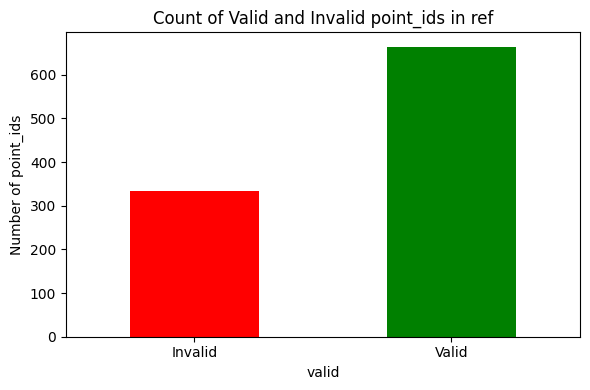

In [115]:
# Visualizing which point_ids are valid in the ref dataframe
import matplotlib.pyplot as plt

# Counting valid and invalid point_ids
valid_counts = ref['valid'].value_counts()

# Ensuring the order is always [False, True] for invalid, valid
ordered_counts = valid_counts.reindex([False, True], fill_value=0)

# Bar plot with correct colors and labels
plt.figure(figsize=(6,4))

ordered_counts.plot(kind='bar', color=['red', 'green'])
plt.xticks([0,1], ['Invalid', 'Valid'], rotation=0)
plt.ylabel('Number of point_ids')
plt.title('Count of Valid and Invalid point_ids in ref')
plt.tight_layout()
plt.show()

In [116]:
invalidation_cause_counts = ref['invalidation_cause'].dropna().value_counts().to_frame(name='Absolute frequency').rename_axis('Invalidation cause')
invalidation_cause_counts['Relative frequency'] = ((invalidation_cause_counts['Absolute frequency'] / invalidation_cause_counts['Absolute frequency'].sum() * 100).round(1).astype(str).add('%'))
invalidation_cause_counts

,Absolute frequency,Relative frequency
Invalidation cause,,
low tree density,144,43.1%
hard to analise,138,41.3%
edge of parcel,37,11.1%
artificial area,15,4.5%


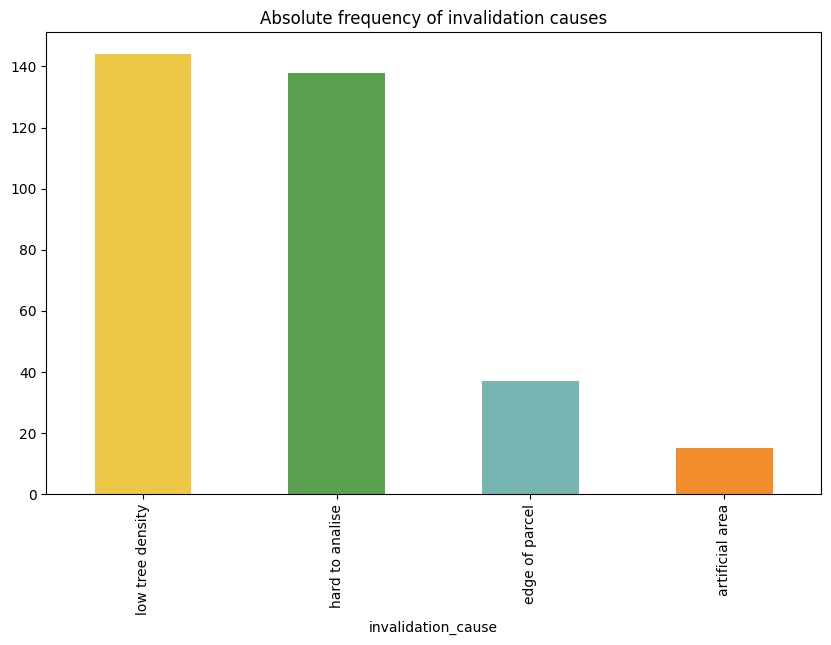

In [117]:
invalidation_cause_counts = ref['invalidation_cause'].dropna().value_counts()
colors = [COLORS_INVALIDATION.get(c, 'gray') for c in invalidation_cause_counts.index]

invalidation_cause_counts.plot.bar(
    title='Absolute frequency of invalidation causes',
    figsize=(10, 6),
    color=colors
)
plt.show()

In [118]:
breaks_counts = ref['breaks'].dropna().str.split(',').explode().str.strip().value_counts().to_frame(name='Absolute frequency').rename_axis('Year')
breaks_counts['Relative frequency'] = ((breaks_counts['Absolute frequency'] / breaks_counts['Absolute frequency'].sum() * 100).round(1).astype(str).add('%'))
breaks_counts

,Absolute frequency,Relative frequency
Year,,
2017,71,9.7%
2003,50,6.8%
2005,40,5.5%
2012,35,4.8%
1991,34,4.6%
1995,29,4.0%
2016,26,3.6%
1990,25,3.4%
2013,24,3.3%


<Axes: title={'center': 'Absolute frequency of breaks per year'}, xlabel='Year'>

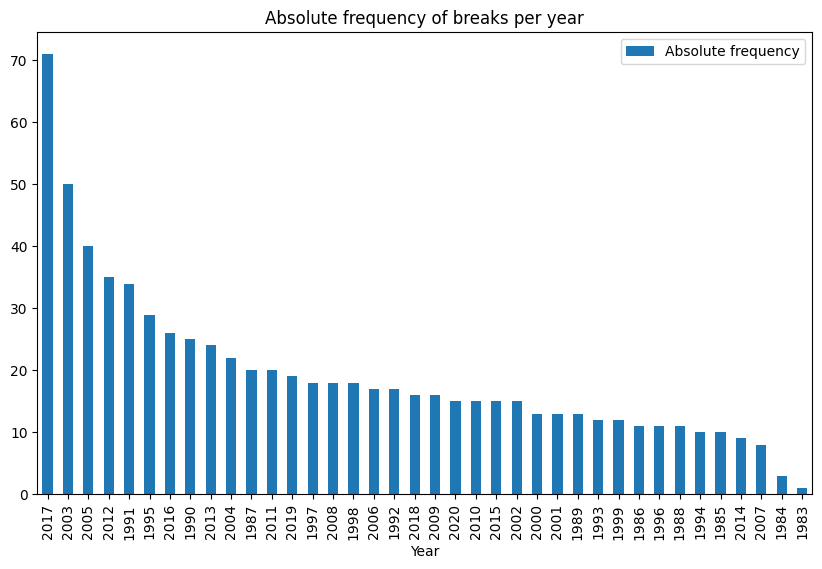

In [119]:
breaks_counts.plot.bar(title='Absolute frequency of breaks per year', figsize=(10, 6))

In [120]:
causes_counts = ref['causes'].dropna().str.split(',').explode().str.strip().value_counts().to_frame(name='Absolute frequency').rename_axis('Cause')
causes_counts = causes_counts.assign(**{'Relative frequency': lambda df: ((df['Absolute frequency'] / df['Absolute frequency'].sum() * 100).round(1).astype(str).add('%'))})
causes_counts

,Absolute frequency,Relative frequency
Cause,,
fire,293,40.0%
harvest,263,35.9%
unknown,169,23.1%
other,7,1.0%


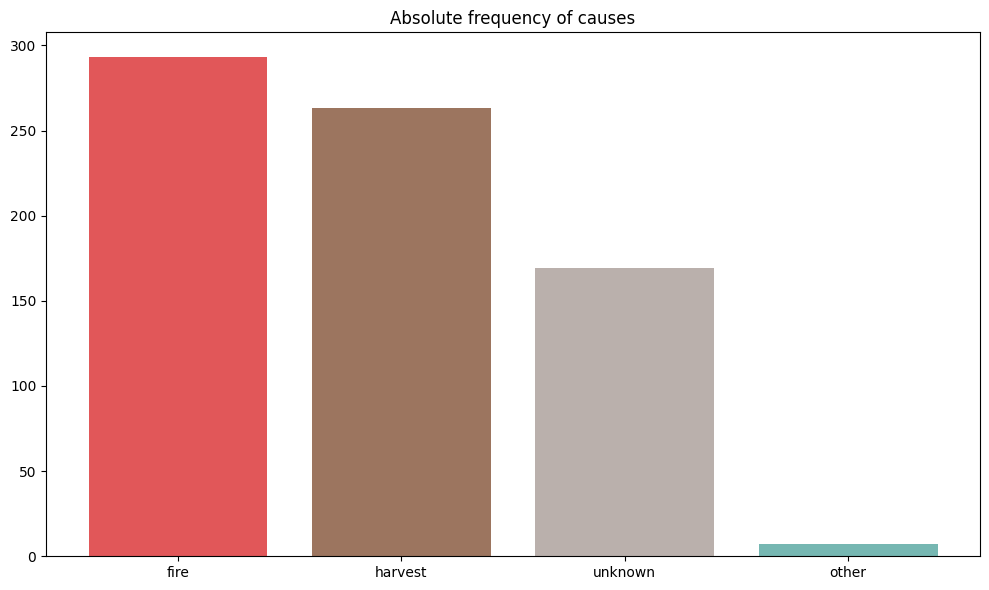

In [121]:
plt.figure(figsize=(10, 6))

for i, idx in enumerate(causes_counts.index):
    plt.bar(idx, causes_counts.loc[idx].values[0], color=COLORS_DISTURBANCE.get(idx, 'gray'))

plt.title('Absolute frequency of causes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Per point

In [190]:
# Picking a point_id
point_id = 747

# Extracting and parsing
row = ref.loc[point_id]
breaks = row['breaks'].split(',') if pd.notnull(row['breaks']) else []
breaks = [int(year.strip()) for year in breaks]

causes = row['causes'].split(',') if pd.notnull(row['causes']) else []
causes = [c.strip() for c in causes]

valid = row['valid']

invalidation_cause = row['invalidation_cause'] if pd.notnull(row['invalidation_cause']) else 'None'

# Combining in a DataFrame
point_disturbances = pd.DataFrame({'Year': breaks, 'Cause': causes})

if valid:
    print('Valid point')
    display(point_disturbances)
else:
    print(f'Invalid point\nInvalidation cause: {invalidation_cause}')

Valid point


,Year,Cause
0,1984,fire
1,1988,harvest
2,1998,harvest
3,2003,fire
4,2012,harvest
5,2017,fire


In [191]:
# Picking a point_id
point_id = 747

# Extracting row for the point
row = ref.loc[point_id]

# Breaks and causes as lists
breaks = [] if pd.isna(row['breaks']) else [int(year.strip()) for year in row['breaks'].split(',')]
causes = [] if pd.isna(row['causes']) else [cause.strip() for cause in row['causes'].split(',')]

# Converting years to a DataFrame with counts
breaks_counts = pd.Series(breaks).value_counts().sort_index().to_frame(name='Absolute frequency').rename_axis('Year')
breaks_counts['Relative frequency'] = (breaks_counts['Absolute frequency'] / breaks_counts['Absolute frequency'].sum() * 100).round(1).astype(str) + '%'
display(breaks_counts)

# Converting causes to a DataFrame with counts
cause_counts = pd.Series(causes).value_counts().to_frame(name='Absolute frequency').rename_axis('Cause')
cause_counts['Relative frequency'] = (cause_counts['Absolute frequency'] / cause_counts['Absolute frequency'].sum() * 100).round(1).astype(str) + '%'
display(cause_counts)

,Absolute frequency,Relative frequency
Year,,
1984,1,16.7%
1988,1,16.7%
1998,1,16.7%
2003,1,16.7%
2012,1,16.7%
2017,1,16.7%


,Absolute frequency,Relative frequency
Cause,,
fire,3,50.0%
harvest,3,50.0%


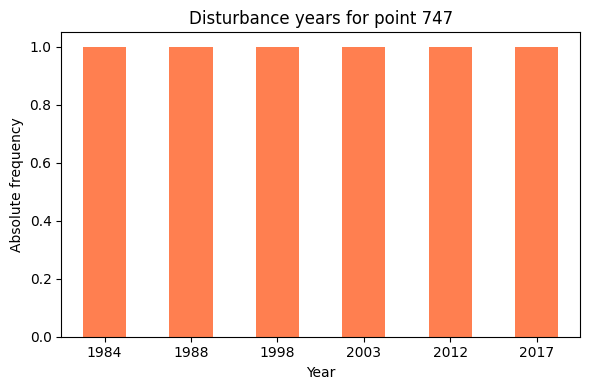

In [192]:
# Plotting break counts if not empty
if not breaks_counts.empty:
    plt.figure(figsize=(6, 4))
    breaks_counts['Absolute frequency'].plot(kind='bar', color='coral')

    plt.title(f'Disturbance years for point {point_id}')
    plt.xlabel('Year')
    plt.ylabel('Absolute frequency')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

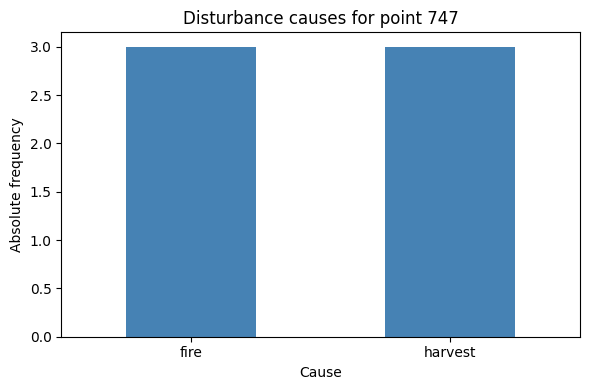

In [193]:
# Plotting cause counts if not empty
if not cause_counts.empty:
    plt.figure(figsize=(6, 4))
    cause_counts['Absolute frequency'].plot(kind='bar', color='steelblue')

    plt.title(f'Disturbance causes for point {point_id}')
    plt.xlabel('Cause')
    plt.ylabel('Absolute frequency')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

### **Changes**

#### Changes per point

In [126]:
# Counting number of changes per point_id and converting to DataFrame
changes_counts = (
    changes['point_id']
    .value_counts()
    .to_frame(name='Absolute frequency')
    .rename_axis('Point ID')
)

# Calculating relative frequency (percent of total points)
changes_counts['Relative frequency'] = (
    (changes_counts['Absolute frequency'] / changes_counts['Absolute frequency'].sum() * 100)
    .round(1)
    .astype(str)
    .add('%')
)

changes_counts.head(10)

,Absolute frequency,Relative frequency
Point ID,,
747,6,0.8%
748,5,0.7%
175,4,0.5%
721,4,0.5%
236,4,0.5%
840,4,0.5%
760,4,0.5%
806,4,0.5%
246,4,0.5%


In [127]:
# Counting changes per point_id and converting to DataFrame
changes_per_point = changes['point_id'].value_counts()

# Converting to DataFrame like your example
counts_df = changes_per_point.value_counts().to_frame(name='Absolute frequency').sort_index()
counts_df.index.name = 'Number of Changes'

# Calculating relative frequency as percent string with 1 decimal
counts_df['Relative frequency'] = (
    (counts_df['Absolute frequency'] / counts_df['Absolute frequency'].sum() * 100)
    .round(1)
    .astype(str)
    .add('%')
)

counts_df

,Absolute frequency,Relative frequency
Number of Changes,,
1,167,43.3%
2,113,29.3%
3,88,22.8%
4,16,4.1%
5,1,0.3%
6,1,0.3%


Text(0.5, 1.0, 'Distribution of number of changes per point')

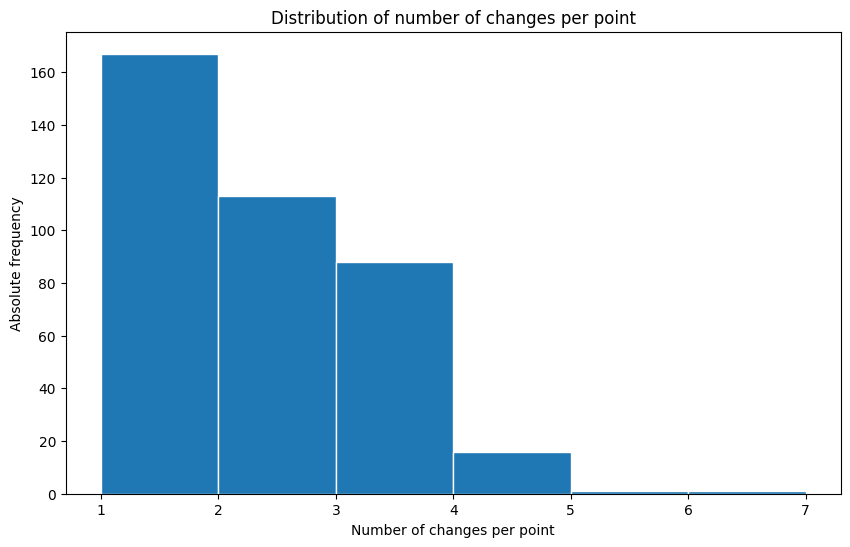

In [128]:
# Counting changes per point_id
changes_per_point = changes['point_id'].value_counts().to_frame(name='num_changes')

# Plotting histogram using pandas .hist() syntax similar to your example
hist = changes_per_point.hist(
    column=["num_changes"],
    grid=False,
    bins=range(1, changes_per_point['num_changes'].max() + 2),
    figsize=(10, 6),
    edgecolor='white'
)[0][0]

hist.set_xlabel('Number of changes per point')
hist.set_ylabel('Absolute frequency')
hist.set_title('Distribution of number of changes per point')

#### Changes per year - Statistics and Box plots

In [129]:
changes['year'].describe()

count     732.000000
mean     2003.990437
std        10.295294
min      1983.000000
25%      1995.000000
50%      2004.000000
75%      2013.000000
max      2020.000000
Name: year, dtype: float64

#### Changes vs Year - Histogram

In [130]:
changes.sort_values(by='year', ascending=True)

,year,cause,point_id
80,1983,fire,144
708,1984,fire,892
404,1984,fire,454
525,1984,fire,747
135,1985,fire,176
...,...,...,...
425,2020,harvest,496
389,2020,harvest,435
176,2020,harvest,203
304,2020,other,343


Text(0.5, 1.0, 'Changes per year')

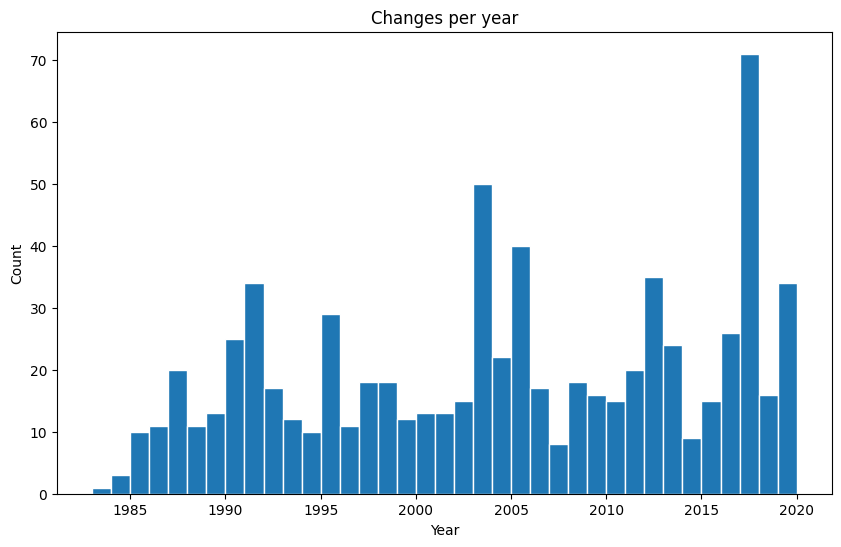

In [131]:
hist = changes.hist(column=["year"], grid=False, bins=(max(changes['year']) - min(changes['year'])), figsize=(10, 6), edgecolor='white')[0][0]
hist.set_xlabel('Year')
hist.set_ylabel('Count')
hist.set_title('Changes per year')

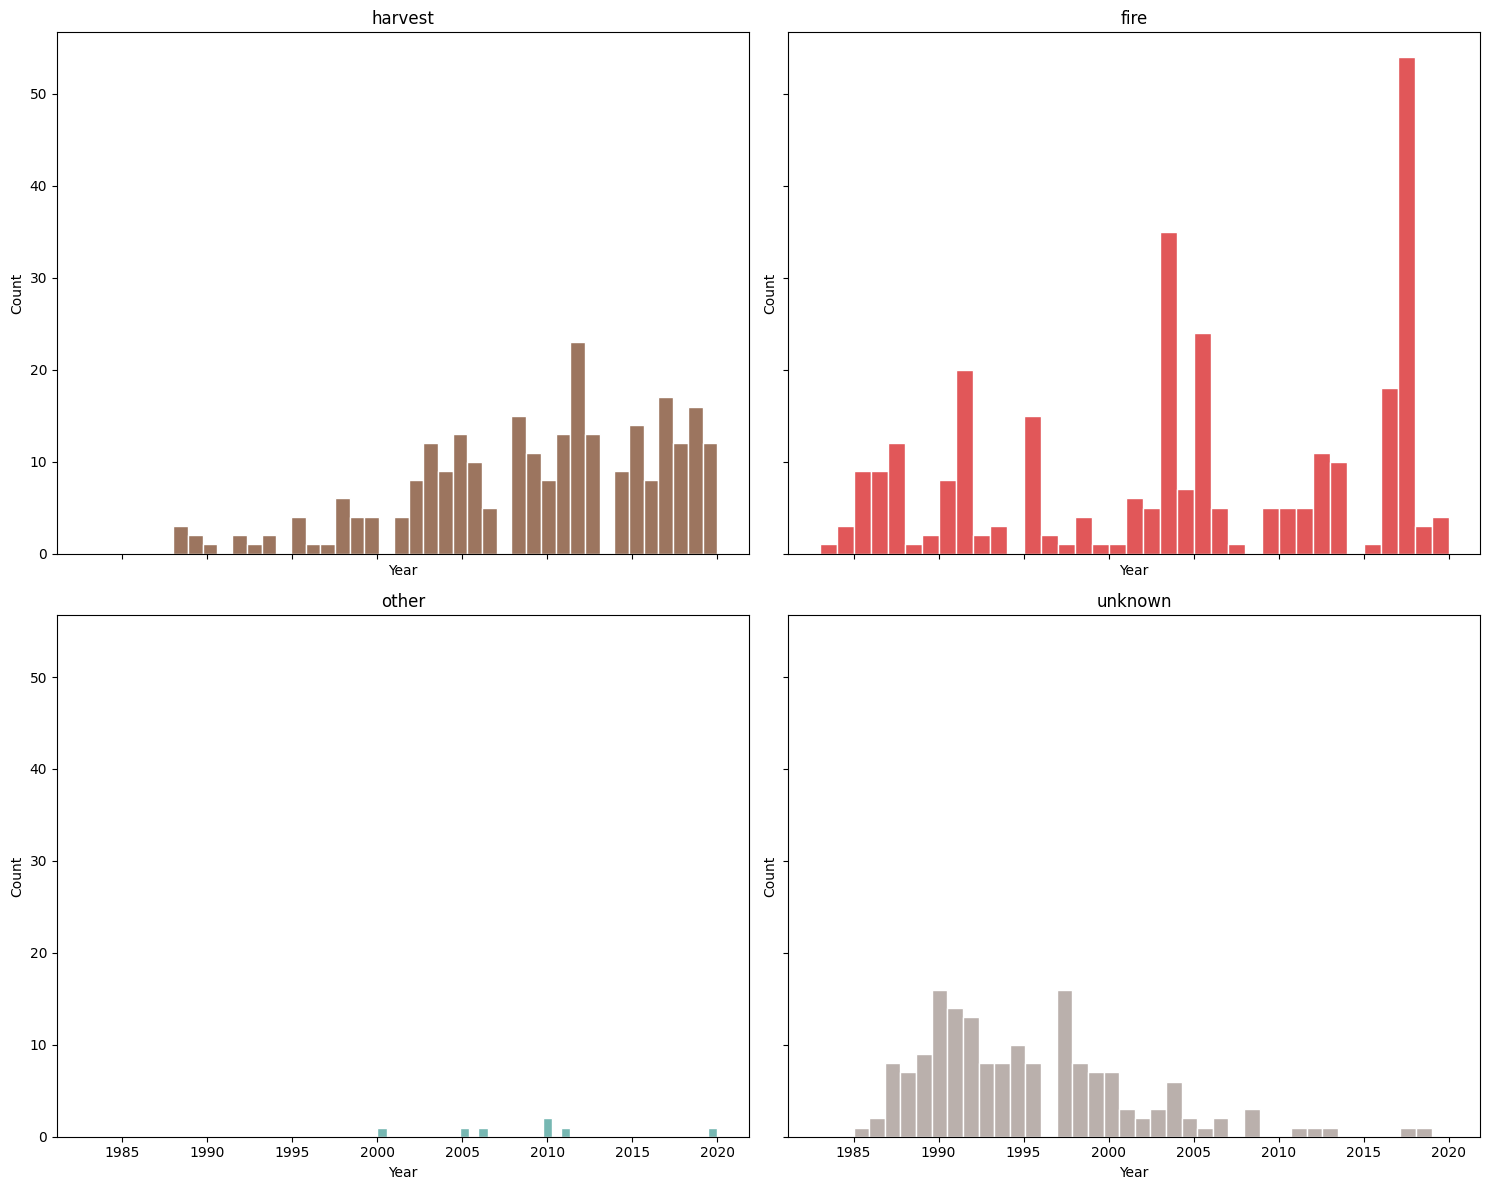

In [132]:
import matplotlib.pyplot as plt

causes = changes['cause'].unique()
colors = [COLORS_DISTURBANCE.get(c, 'gray') for c in causes]

fig, axes = plt.subplots(2, 2, figsize=(15, 12), sharex=True, sharey=True)
axes = axes.flatten()

for i, cause in enumerate(causes):
    ax = axes[i]
    changes[changes['cause'] == cause]['year'].hist(
        bins=max(changes['year']) - min(changes['year']), edgecolor='white', color=colors[i], ax=ax
    )
    ax.set_title(cause)
    ax.set_xlabel('Year')
    ax.set_ylabel('Count')
    ax.grid(False)  # Remove gridlines

plt.tight_layout()
plt.show()

#### Changes vs year - Bar chart

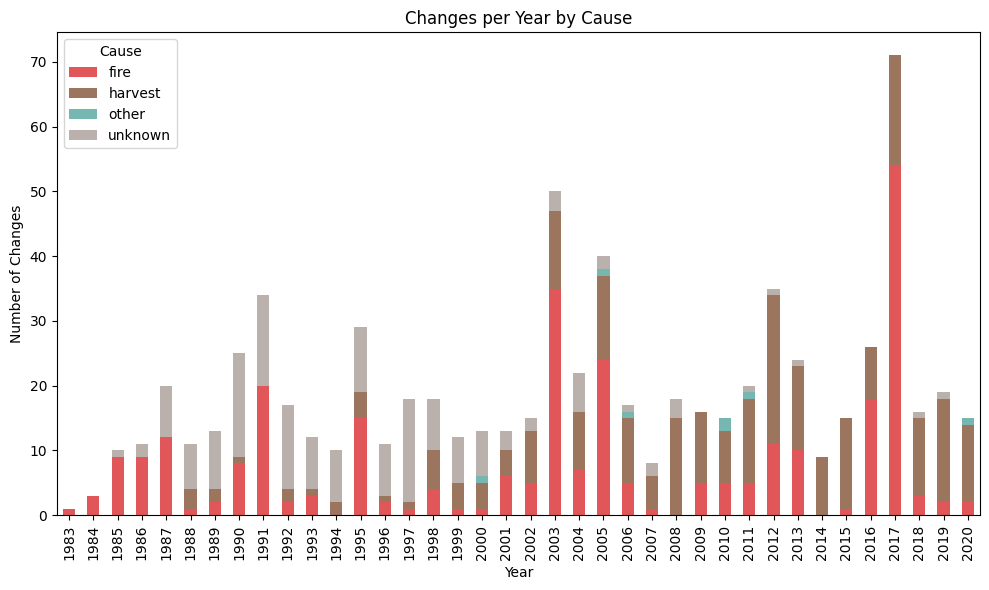

In [133]:
import pandas as pd
import matplotlib.pyplot as plt

# Group by year and cause, then count number of occurrences
grouped = changes.groupby(['year', 'cause']).size().unstack(fill_value=0)

# Plot as stacked bar chart
grouped.sort_index().plot(kind='bar', stacked=True, color=[COLORS_DISTURBANCE.get(c) for c in grouped.columns], figsize=(10, 6))

# Reorder the columns to match the desired order
desired_order = ['harvest', 'fire', 'unknown', 'other']
grouped = grouped.reindex(columns=desired_order)

# Plot configuration
plt.xlabel('Year')
plt.ylabel('Number of Changes')
plt.title('Changes per Year by Cause')
plt.legend(title='Cause')
plt.tight_layout()
plt.show()

As we can see, most of the causes are fires. The number of unknown causes heavily decreases as we get closer to the present, most probably due to the better identification of harvests (as the number of harvests as the cause increase over time)

#### Changes vs Year - Scatter with lin reg

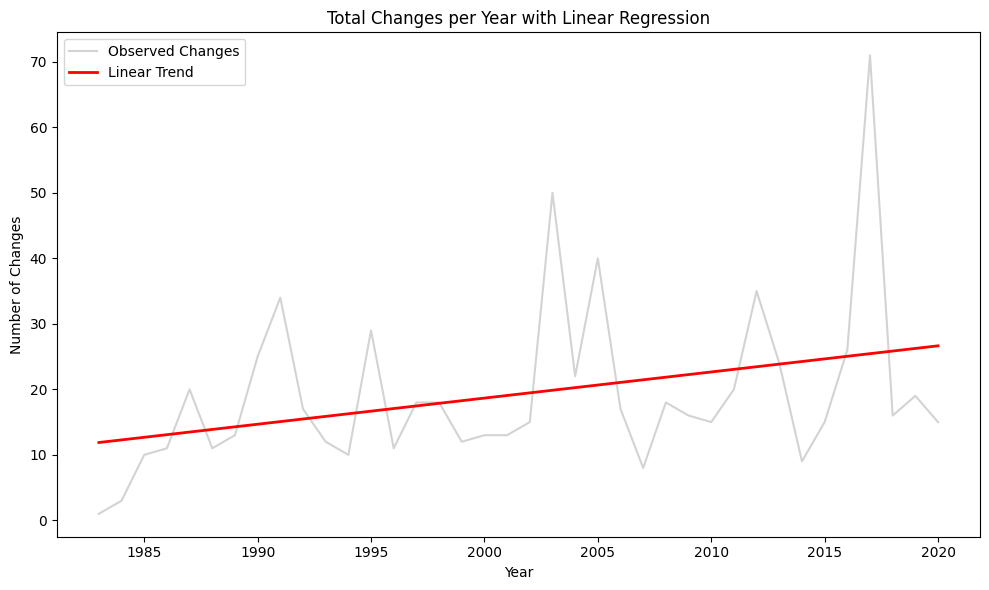

In [134]:
year_counts = changes['year'].value_counts().sort_index() # Series: index = year; value = count
#year_counts.plot(kind='line')

#define variables
x = year_counts.index.values.reshape(-1, 1)    # x = years  #".index" returns only 1st column from the Series "year_counts". ".values" necessary to transform Index in array that can be then reshaped
y = year_counts.values                    # y = counts #".values" returns only 2nd column from the Series "year_counts"

#perform linear regression
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

#plot regression results
plt.figure(figsize=(10, 6))
plt.plot(x.flatten(), y, color='lightgray', label='Observed Changes')
plt.plot(x.flatten(), y_pred, color='red', linewidth=2, label='Linear Trend')

plt.xlabel('Year')
plt.ylabel('Number of Changes')
plt.title('Total Changes per Year with Linear Regression')
plt.legend()
plt.tight_layout()
plt.show()

With these results, we can see that the amount of changes per year increased over time. The most likely reason is that the amount of data collected increased over the years (and not an actual increase in wildfires over the years)

### **Changepoints**

#### Overview

##### Statistics

In [135]:
changepts['NBR'].dropna().describe()

count    792792.000000
mean          0.391355
std           0.214294
min          -0.936947
25%           0.227748
50%           0.395389
75%           0.556031
max           0.998742
Name: NBR, dtype: float64

In [136]:
changepts['NDVI'].dropna().describe()

count    793350.000000
mean          0.428271
std           0.138832
min          -0.989075
25%           0.330434
50%           0.434230
75%           0.529028
max           0.979819
Name: NDVI, dtype: float64

##### Box plots

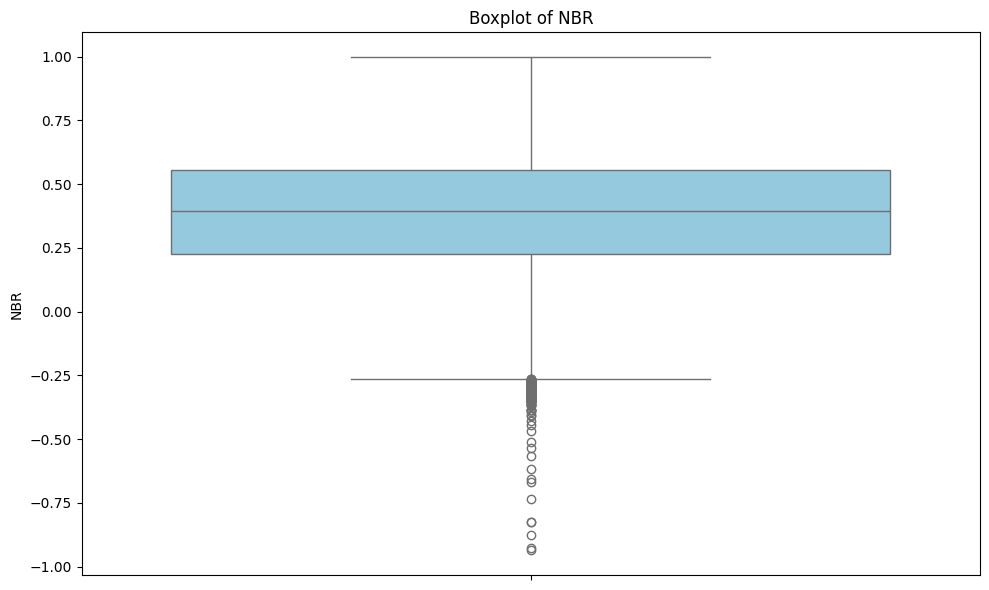

In [137]:
nbr = changepts['NBR'].dropna()
plt.figure(figsize=(10, 6))
sns.boxplot(y=nbr, color='skyblue')
plt.title('Boxplot of NBR')
plt.ylabel('NBR')
plt.tight_layout()
plt.show()

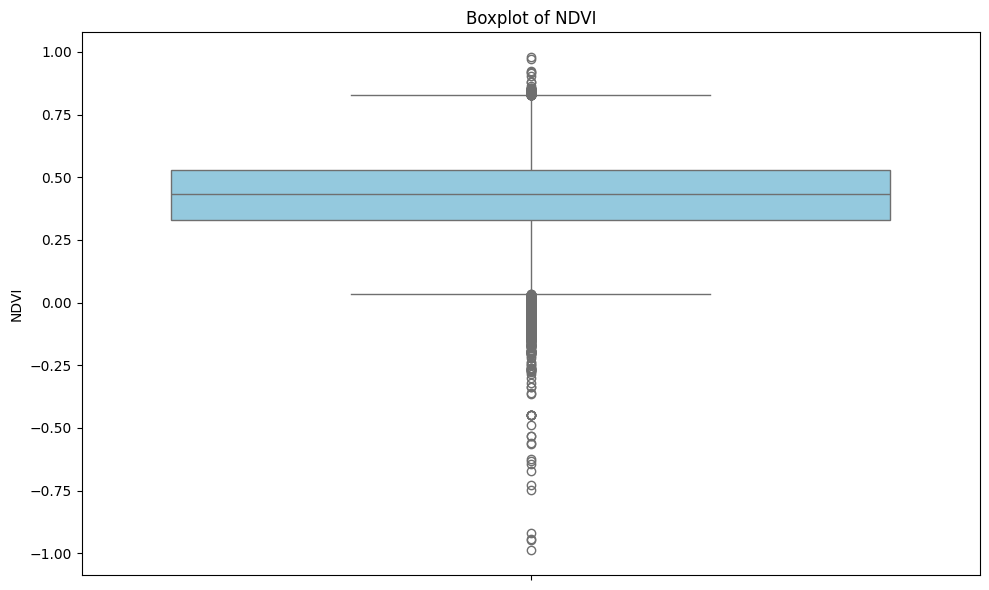

In [138]:
ndvi = changepts['NDVI'].dropna()
plt.figure(figsize=(10, 6))
sns.boxplot(y=ndvi, color='skyblue')
plt.title('Boxplot of NDVI')
plt.ylabel('NDVI')
plt.tight_layout()
plt.show()

##### Scatter plots

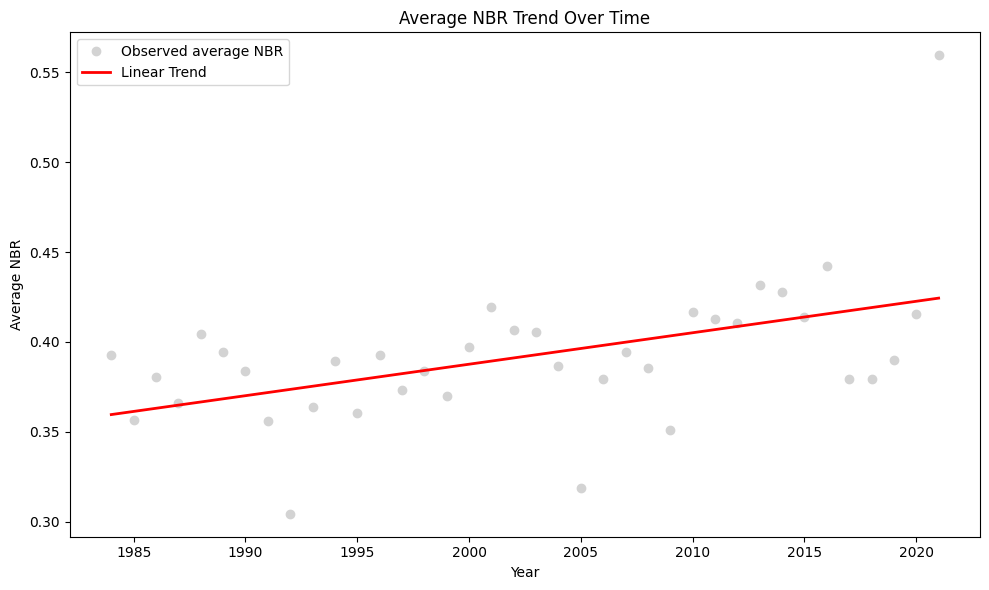

In [139]:
#NBR vs year + lin reg

# Drop NaNs and compute average NBR per year
changepts_no_na = changepts.dropna(subset=['NBR'])
avg_nbr = changepts_no_na.groupby(changepts_no_na.index.year)['NBR'].mean()

# Prepare data
x = avg_nbr.index.values.reshape(-1, 1)
y = avg_nbr.values

#perform linear regression
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

#plot regression results
plt.figure(figsize=(10, 6))

plt.plot(x.flatten(), y, 'o', color='lightgray', label='Observed average NBR')
plt.plot(x.flatten(), y_pred, color='red', linewidth=2, label='Linear Trend')

plt.xlabel('Year')
plt.ylabel('Average NBR')
plt.title('Average NBR Trend Over Time')
plt.legend()
plt.tight_layout()
plt.show()

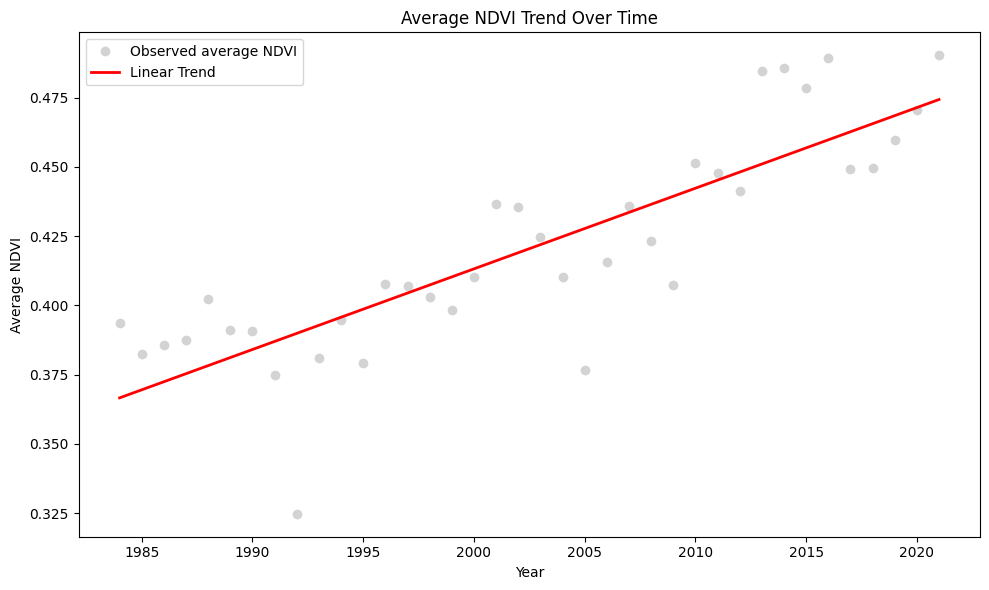

In [140]:
#NDVI vs year + lin reg

# Drop NaNs and compute average NBR per year
changepts_no_na = changepts.dropna(subset=['NDVI'])
avg_ndvi = changepts_no_na.groupby(changepts_no_na.index.year)['NDVI'].mean()

# Prepare data
x = avg_ndvi.index.values.reshape(-1, 1)
y = avg_ndvi.values

#perform linear regression
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

#plot regression results
plt.figure(figsize=(10, 6))

plt.plot(x.flatten(), y, 'o', color='lightgray', label='Observed average NDVI')
plt.plot(x.flatten(), y_pred, color='red', linewidth=2, label='Linear Trend')

plt.xlabel('Year')
plt.ylabel('Average NDVI')
plt.title('Average NDVI Trend Over Time')
plt.legend()
plt.tight_layout()
plt.show()

##### Line plot

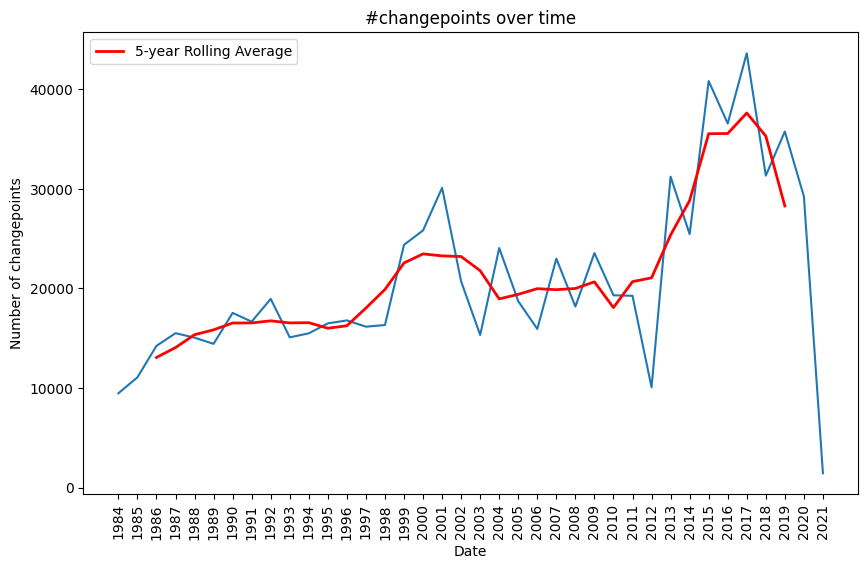

In [141]:
# Number of changepoints vs year

year_counts = changepts.index.year.value_counts().sort_index() # Series: index = date; value = count

# Apply rolling average (5-year window)
rolling_window = 5
y_smoothed = year_counts.rolling(window=rolling_window, center=True).mean()

x = year_counts.index
y = year_counts.values

plt.figure(figsize=(10, 6))

plt.plot(x, y)
plt.plot(x, y_smoothed, color='red', linewidth=2, label=f'{rolling_window}-year Rolling Average')

plt.xticks(ticks=x, rotation=90)

plt.xlabel('Date')
plt.ylabel('Number of changepoints')
plt.title('#changepoints over time')
plt.legend()

plt.show()


Amount of data collected increased in later years (higher number of changepoints).

##### Kernel density estimation

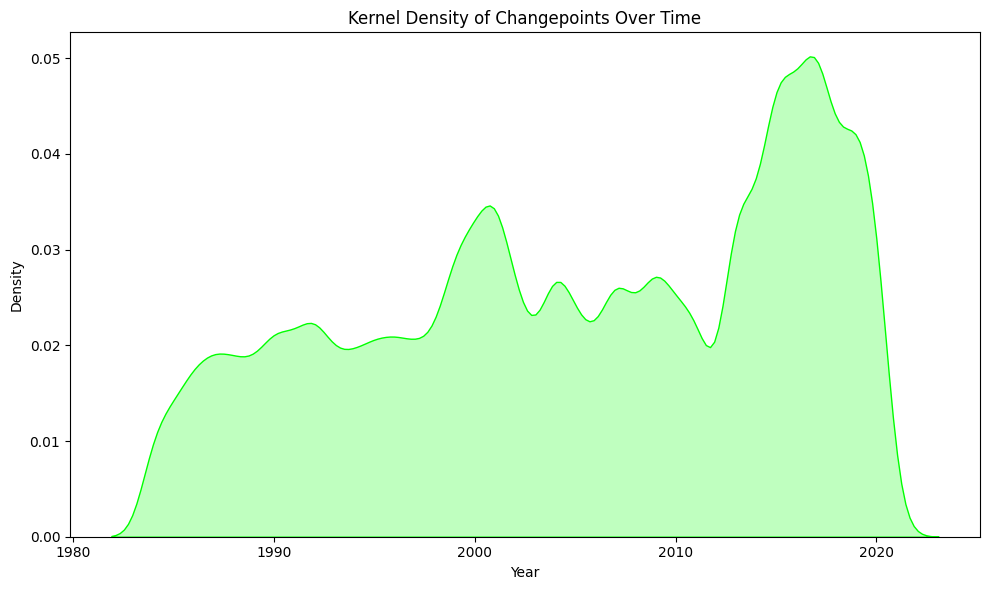

In [142]:
years = changepts.index.year

# Plot KDE
plt.figure(figsize=(10, 6))
sns.kdeplot(years, bw_adjust=1, fill=True, color='lime')

plt.xlabel('Year')
plt.ylabel('Density')
plt.title('Kernel Density of Changepoints Over Time')
plt.tight_layout()
plt.show()

#### Per point

##### Statistics

In [143]:
point_id = 1

changepts_point = changepts[changepts['point_id'] == point_id]

changepts_point['NBR'].dropna().describe()

count    515.000000
mean       0.562716
std        0.147133
min        0.103171
25%        0.478393
50%        0.591929
75%        0.668633
max        0.827848
Name: NBR, dtype: float64

In [144]:
point_id = 1

changepts_point = changepts[changepts['point_id'] == point_id]

changepts_point['NDVI'].dropna().describe()

count    515.000000
mean       0.567654
std        0.071892
min        0.158154
25%        0.526354
50%        0.574657
75%        0.616132
max        0.754654
Name: NDVI, dtype: float64

##### Box plots

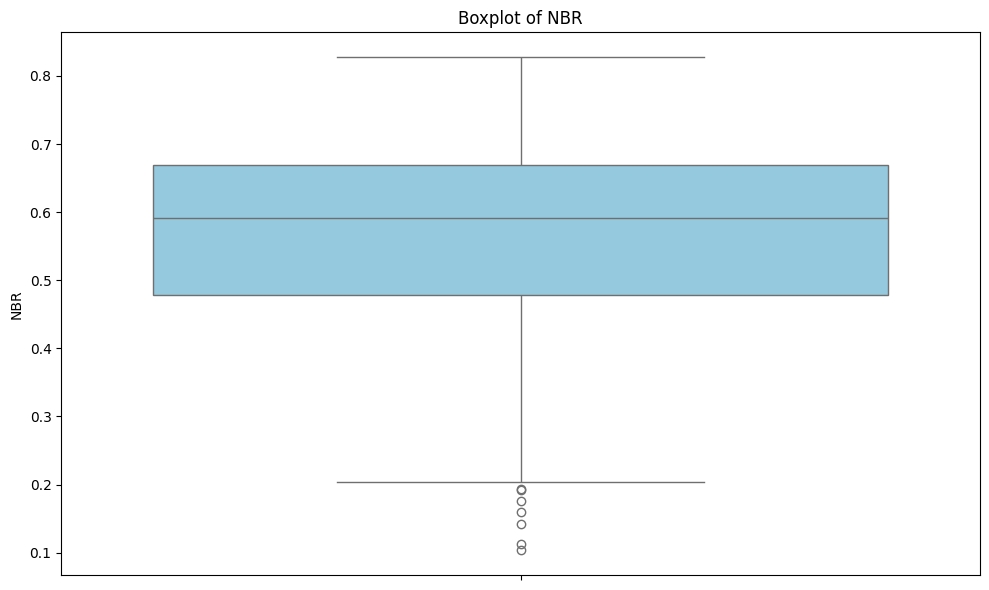

In [145]:
point_id = 1

changepts_point = changepts[changepts['point_id'] == point_id]

nbr_point = changepts_point['NBR'].dropna()

plt.figure(figsize=(10, 6))
sns.boxplot(y=nbr_point, color='skyblue')
plt.title('Boxplot of NBR')
plt.ylabel('NBR')
plt.tight_layout()
plt.show()

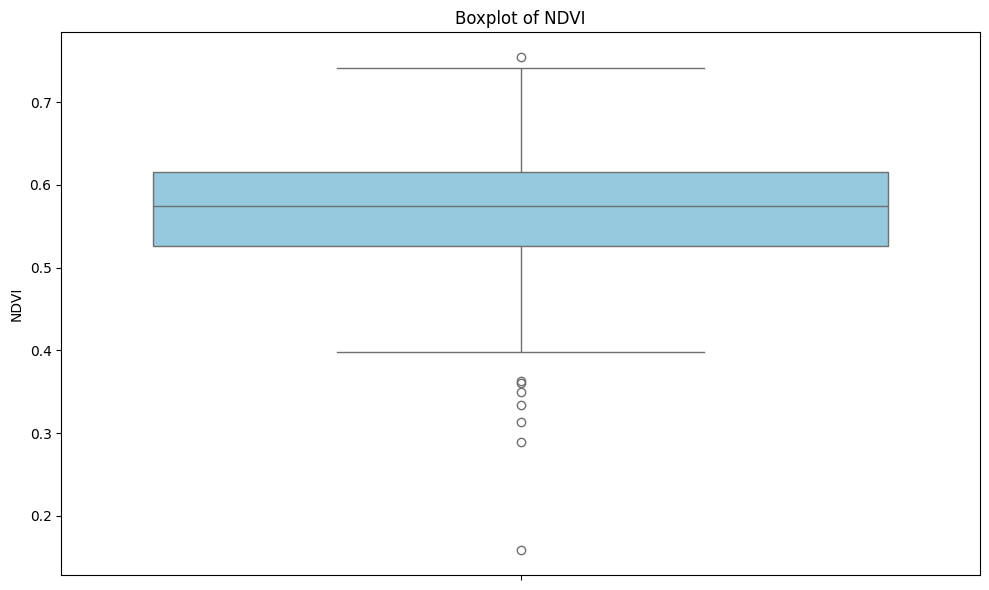

In [146]:
point_id = 1

changepts_point = changepts[changepts['point_id'] == point_id]

ndvi_point = changepts_point['NDVI'].dropna()

plt.figure(figsize=(10, 6))
sns.boxplot(y=ndvi_point, color='skyblue')
plt.title('Boxplot of NDVI')
plt.ylabel('NDVI')
plt.tight_layout()
plt.show()

##### Scatter plots

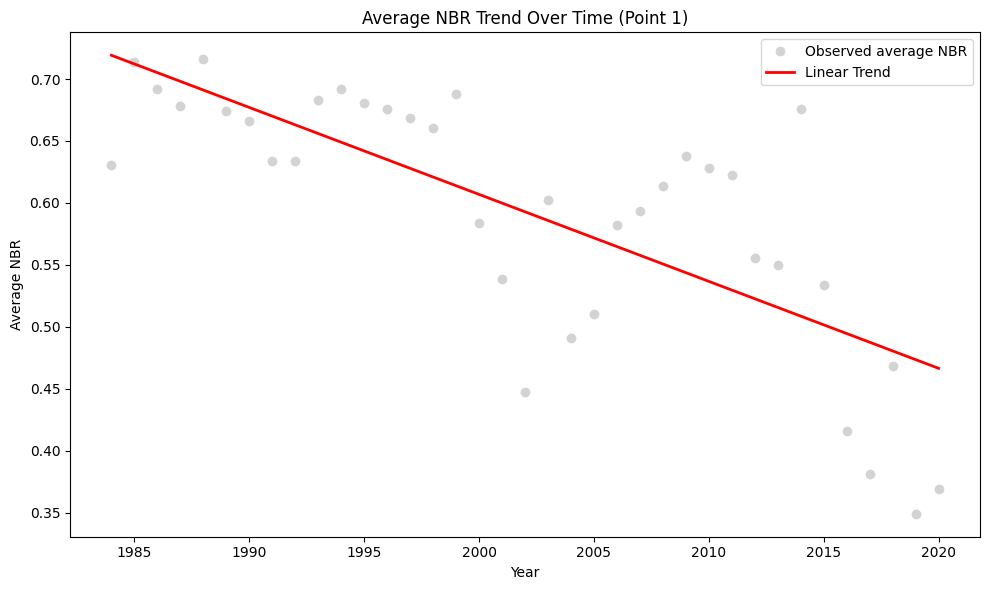

In [147]:
point_id = 1

# Filter by point
changepts_point = changepts[changepts['point_id'] == point_id]

# Drop NaNs and compute average NBR per year
changepts_point_no_na = changepts_point.dropna(subset=['NBR'])
avg_nbr = changepts_point_no_na.groupby(changepts_point_no_na.index.year)['NBR'].mean()

# Prepare data
x = avg_nbr.index.values.reshape(-1, 1)
y = avg_nbr.values

#perform linear regression
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

#plot regression results
plt.figure(figsize=(10, 6))

plt.plot(x.flatten(), y, 'o', color='lightgray', label='Observed average NBR')
plt.plot(x.flatten(), y_pred, color='red', linewidth=2, label='Linear Trend')

plt.xlabel('Year')
plt.ylabel('Average NBR')
plt.title(f'Average NBR Trend Over Time (Point {point_id})')
plt.legend()
plt.tight_layout()
plt.show()

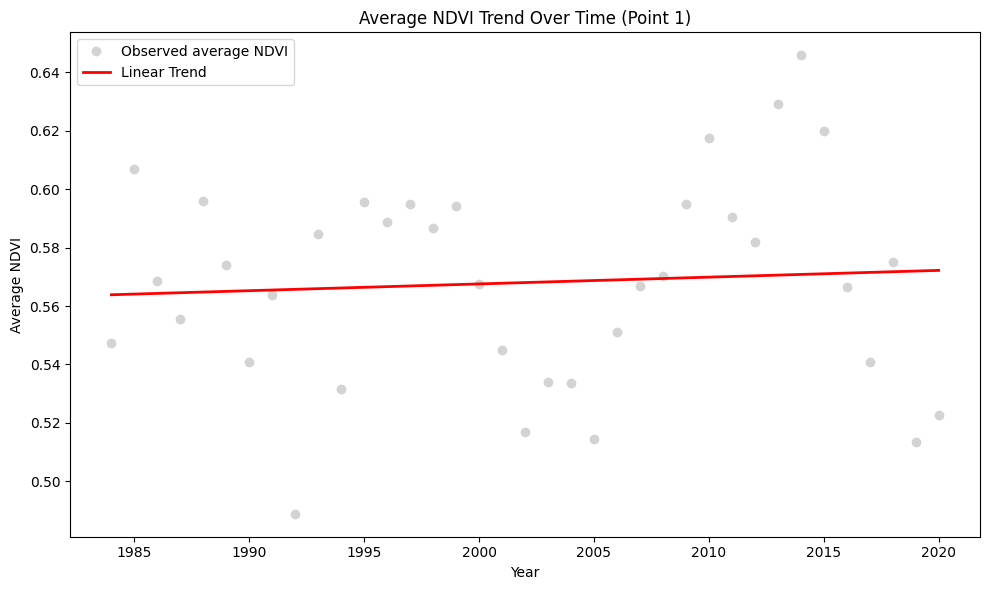

In [148]:
point_id = 1

# Filter by point
changepts_point = changepts[changepts['point_id'] == point_id]

# Drop NaNs and compute average NDVI per year
changepts_point_no_na = changepts_point.dropna(subset=['NDVI'])
avg_ndvi = changepts_point_no_na.groupby(changepts_point_no_na.index.year)['NDVI'].mean()

# Prepare data
x = avg_ndvi.index.values.reshape(-1, 1)
y = avg_ndvi.values

#perform linear regression
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

#plot regression results
plt.figure(figsize=(10, 6))

plt.plot(x.flatten(), y, 'o', color='lightgray', label='Observed average NDVI')
plt.plot(x.flatten(), y_pred, color='red', linewidth=2, label='Linear Trend')

plt.xlabel('Year')
plt.ylabel('Average NDVI')
plt.title(f'Average NDVI Trend Over Time (Point {point_id})')
plt.legend()
plt.tight_layout()
plt.show()

##### Line plot

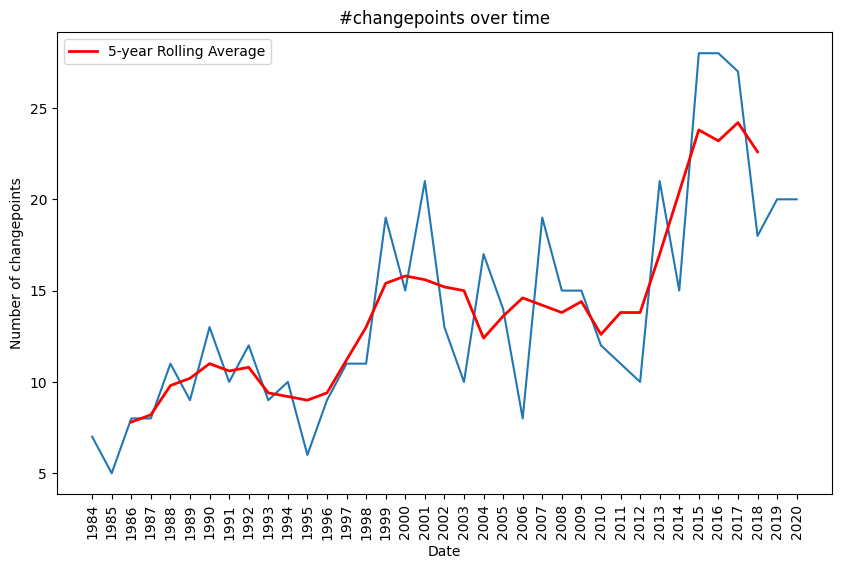

In [149]:
point_id = 1

# Filter by point
changepts_point = changepts[changepts['point_id'] == point_id]

# Number of changepoints vs year

year_counts = changepts_point.index.year.value_counts().sort_index() # Series: index = date; value = count

# Apply rolling average (5-year window)
rolling_window = 5
y_smoothed = year_counts.rolling(window=rolling_window, center=True).mean()

x = year_counts.index
y = year_counts.values

plt.figure(figsize=(10, 6))

plt.plot(x, y)
plt.plot(x, y_smoothed, color='red', linewidth=2, label=f'{rolling_window}-year Rolling Average')

plt.xticks(ticks=x, rotation=90)

plt.xlabel('Date')
plt.ylabel('Number of changepoints')
plt.title('#changepoints over time')
plt.legend()

plt.show()


##### Kernel density estimation

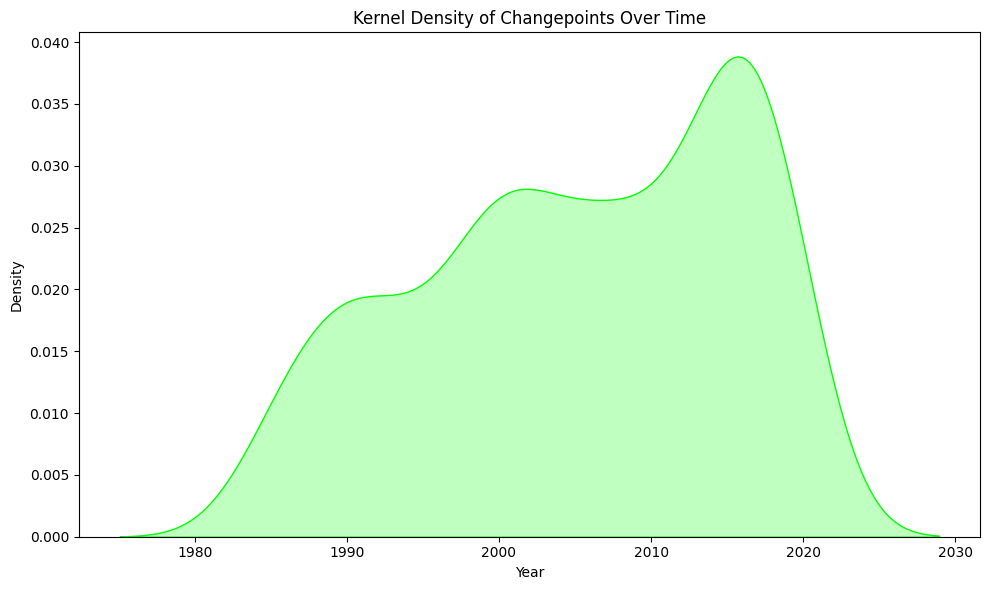

In [150]:
point_id = 1

# Filter by point
changepts_point = changepts[changepts['point_id'] == point_id]

years = changepts_point.index.year

# Plot KDE
plt.figure(figsize=(10, 6))
sns.kdeplot(years, bw_adjust=1, fill=True, color='lime')

plt.xlabel('Year')
plt.ylabel('Density')
plt.title('Kernel Density of Changepoints Over Time')
plt.tight_layout()
plt.show()

## Task 3 – Performing EDA

- Process and clean the reference data to create `ref_processed` with MultiIndex structure
- Aggregate changepoints data by month and year with statistical measures (mean, std, min, max, median)
- Handle missing data through interpolation
- Create time series visualizations showing disturbance patterns for specific point_ids
- Perform dimensionality reduction on aggregated features


#### Correlation between statistics per point

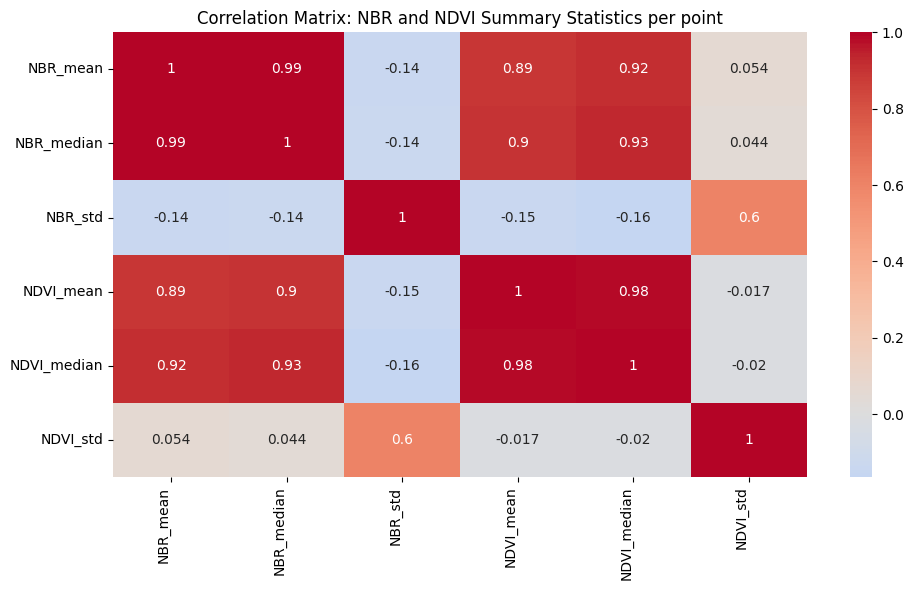

In [151]:
# Computing stats per point_id
stats = changepts.groupby('point_id').agg({
    'NBR': ['mean', 'median', 'std'],
    'NDVI': ['mean', 'median', 'std']
})

# Flattenning column names
stats.columns = ['_'.join(col) for col in stats.columns]

# Computing correlation
corr_matrix = stats.corr()

# Plotting heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix: NBR and NDVI Summary Statistics per point')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

#### Data processing of reference

In [152]:
# Filtering for valid point_ids
ref_valid = ref[ref['valid'] == True].copy()

# Splitting 'breaks' and 'causes' into lists
ref_valid['breaks'] = ref_valid['breaks'].fillna('').astype(str).str.split(',')
ref_valid['causes'] = ref_valid['causes'].fillna('').astype(str).str.split(',')

# Removing whitespace from each entry in the lists
ref_valid['breaks'] = ref_valid['breaks'].apply(lambda lst: [x.strip() for x in lst if x.strip() != ''])
ref_valid['causes'] = ref_valid['causes'].apply(lambda lst: [x.strip() for x in lst if x.strip() != ''])

# Exploding both columns
ref_exploded = ref_valid.explode(['breaks', 'causes'])

# Removing rows where either 'breaks' or 'causes' is empty (in case of missing data)
ref_exploded = ref_exploded[(ref_exploded['breaks'] != '') & (ref_exploded['causes'] != '')]

# Creating a multi-index with point_id and breaks
ref_exploded = ref_exploded.reset_index()
ref_exploded = ref_exploded.set_index(['point_id', 'breaks'])
ref_exploded

causes  valid invalidation_cause
point_id breaks                                   
1        2012    harvest   True                NaN
         2016    harvest   True                NaN
5        NaN         NaN   True                NaN
7        NaN         NaN   True                NaN
8        NaN         NaN   True                NaN
...                  ...    ...                ...
989      2004    unknown   True                NaN
991      1997    unknown   True                NaN
994      NaN         NaN   True                NaN
995      NaN         NaN   True                NaN
998      NaN         NaN   True                NaN

[1010 rows x 3 columns]

In [153]:
ref_processed = ref_exploded[['causes']].dropna()
ref_processed

causes
point_id breaks         
1        2012    harvest
         2016    harvest
50       2004       fire
57       2005      other
70       2012       fire
...                  ...
979      1992    unknown
988      2001    unknown
989      1987    unknown
         2004    unknown
991      1997    unknown

[732 rows x 1 columns]

We are left with a dataframe with all the breaks from 1983 to 2020 per point_id with the respective cause

#### Aggregation and interpolation fo fill missing data in changepoints

First, we will sort the "changepts" DataFrame by point_id and aggregate the data monthly by mean, std, min, max, median

In [154]:
changepts_stacked = changepts.reset_index().set_index(['point_id','Date']).sort_index()

# Grouping by point_id and month, and aggregating with multiple statistics
changepts_month = changepts_stacked.groupby(
    ['point_id', pd.Grouper(level=1, freq='M')]
).agg({
    'NBR': ['mean', 'std', 'min', 'max', 'median'],
    'NDVI': ['mean', 'std', 'min', 'max', 'median']
})

# Converting DateTimeIndex to PeriodIndex
changepts_month = changepts_month.copy()
changepts_month.index = changepts_month.index.set_levels(
    [changepts_month.index.levels[0], 
     changepts_month.index.levels[1].to_period('M')]
)

changepts_month

C:\Users\Pedro\AppData\Local\Temp\ipykernel_22792\3096772818.py:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  ['point_id', pd.Grouper(level=1, freq='M')]


NBR                                              NDVI  \
                      mean       std       min       max    median      mean   
point_id Date                                                                  
1        1984-04  0.470472       NaN  0.470472  0.470472  0.470472  0.426005   
         1984-05  0.593581       NaN  0.593581  0.593581  0.593581  0.437981   
         1984-07  0.662161       NaN  0.662161  0.662161  0.662161  0.606930   
         1984-09  0.668384  0.052740  0.634656  0.729161  0.641334  0.595619   
         1984-11  0.681281       NaN  0.681281  0.681281  0.681281  0.574660   
...                    ...       ...       ...       ...       ...       ...   
998      2020-09  0.454099  0.026659  0.426153  0.493611  0.446657  0.561146   
         2020-10  0.518413  0.045799  0.486029  0.550798  0.518413  0.611245   
         2020-11  0.481517       NaN  0.481517  0.481517  0.481517  0.500545   
         2020-12  0.528298  0.023055  0.511995  0.544600  0.528298  0.574112   
         2021-02  0.444107       NaN  0.444107  0.444107  0.444107  0.589744   

                                                          
                       std       min       max    median  
point_id Date                                             
1        1984-04       NaN  0.426005  0.426005  0.426005  
         1984-05       NaN  0.437981  0.437981  0.437981  
         1984-07       NaN  0.606930  0.606930  0.606930  
         1984-09  0.052531  0.547408  0.651604  0.587845  
         1984-11       NaN  0.574660  0.574660  0.574660  
...                    ...       ...       ...       ...  
998      2020-09  0.040078  0.500952  0.606049  0.569412  
         2020-10  0.050024  0.575873  0.646618  0.611245  
         2020-11       NaN  0.500545  0.500545  0.500545  
         2020-12  0.061262  0.530793  0.617431  0.574112  
         2021-02       NaN  0.589744  0.589744  0.589744  

[346566 rows x 10 columns]

In [155]:
# Flattening the MultiIndex columns
changepts_month.columns = ['_'.join(col).strip() for col in changepts_month.columns.values]

# Flatenning necessary
# Before flatenning:
# NBR                 NDVI
#    mean std min ...   mean std min ...
# 0   ...  ... ...      ...  ... ...
# After flatenning:
# NBR_mean NBR_std NBR_min ... NDVI_mean NDVI_std NDVI_min ...
# 0   ...  ... ...      ...  ... ...

changepts_month

NBR_mean   NBR_std   NBR_min   NBR_max  NBR_median  \
point_id Date                                                          
1        1984-04  0.470472       NaN  0.470472  0.470472    0.470472   
         1984-05  0.593581       NaN  0.593581  0.593581    0.593581   
         1984-07  0.662161       NaN  0.662161  0.662161    0.662161   
         1984-09  0.668384  0.052740  0.634656  0.729161    0.641334   
         1984-11  0.681281       NaN  0.681281  0.681281    0.681281   
...                    ...       ...       ...       ...         ...   
998      2020-09  0.454099  0.026659  0.426153  0.493611    0.446657   
         2020-10  0.518413  0.045799  0.486029  0.550798    0.518413   
         2020-11  0.481517       NaN  0.481517  0.481517    0.481517   
         2020-12  0.528298  0.023055  0.511995  0.544600    0.528298   
         2021-02  0.444107       NaN  0.444107  0.444107    0.444107   

                  NDVI_mean  NDVI_std  NDVI_min  NDVI_max  NDVI_median  
point_id Date                                                           
1        1984-04   0.426005       NaN  0.426005  0.426005     0.426005  
         1984-05   0.437981       NaN  0.437981  0.437981     0.437981  
         1984-07   0.606930       NaN  0.606930  0.606930     0.606930  
         1984-09   0.595619  0.052531  0.547408  0.651604     0.587845  
         1984-11   0.574660       NaN  0.574660  0.574660     0.574660  
...                     ...       ...       ...       ...          ...  
998      2020-09   0.561146  0.040078  0.500952  0.606049     0.569412  
         2020-10   0.611245  0.050024  0.575873  0.646618     0.611245  
         2020-11   0.500545       NaN  0.500545  0.500545     0.500545  
         2020-12   0.574112  0.061262  0.530793  0.617431     0.574112  
         2021-02   0.589744       NaN  0.589744  0.589744     0.589744  

[346566 rows x 10 columns]

In [156]:
# Filtering changepts_month to keep only valid point_id's from ref
# Getting valid point_ids
valid_point_ids = ref[ref['valid'] == True].index #.index necessary to get the index of the dataframe

# Filtering changepts_month
changepts_month_valid = changepts_month.loc[changepts_month.index.get_level_values('point_id').isin(valid_point_ids)]

# Displaying the result
display(changepts_month_valid)

# Displaying the number of unique point_id's (level 0 of the MultiIndex)
num_point_ids = changepts_month_valid.index.get_level_values(0).nunique()
print("Number of unique valid point_id's:", num_point_ids)

NBR_mean   NBR_std   NBR_min   NBR_max  NBR_median  \
point_id Date                                                          
1        1984-04  0.470472       NaN  0.470472  0.470472    0.470472   
         1984-05  0.593581       NaN  0.593581  0.593581    0.593581   
         1984-07  0.662161       NaN  0.662161  0.662161    0.662161   
         1984-09  0.668384  0.052740  0.634656  0.729161    0.641334   
         1984-11  0.681281       NaN  0.681281  0.681281    0.681281   
...                    ...       ...       ...       ...         ...   
998      2020-09  0.454099  0.026659  0.426153  0.493611    0.446657   
         2020-10  0.518413  0.045799  0.486029  0.550798    0.518413   
         2020-11  0.481517       NaN  0.481517  0.481517    0.481517   
         2020-12  0.528298  0.023055  0.511995  0.544600    0.528298   
         2021-02  0.444107       NaN  0.444107  0.444107    0.444107   

                  NDVI_mean  NDVI_std  NDVI_min  NDVI_max  NDVI_median  
point_id Date                                                           
1        1984-04   0.426005       NaN  0.426005  0.426005     0.426005  
         1984-05   0.437981       NaN  0.437981  0.437981     0.437981  
         1984-07   0.606930       NaN  0.606930  0.606930     0.606930  
         1984-09   0.595619  0.052531  0.547408  0.651604     0.587845  
         1984-11   0.574660       NaN  0.574660  0.574660     0.574660  
...                     ...       ...       ...       ...          ...  
998      2020-09   0.561146  0.040078  0.500952  0.606049     0.569412  
         2020-10   0.611245  0.050024  0.575873  0.646618     0.611245  
         2020-11   0.500545       NaN  0.500545  0.500545     0.500545  
         2020-12   0.574112  0.061262  0.530793  0.617431     0.574112  
         2021-02   0.589744       NaN  0.589744  0.589744     0.589744  

[230878 rows x 10 columns]

Number of unique valid point_id's: 664


"Number of unique valid point_id's: 664" checks out with the number of valid point_id's in ref (Seen in Task 2)

In [157]:
import pandas as pd

# Getting all unique point_ids from changepts_month
point_ids = changepts_month.index.get_level_values('point_id').unique()

# Getting the full range of months in your data
all_months = pd.period_range(
    start=changepts_month.index.get_level_values('Date').min(),
    end=changepts_month.index.get_level_values('Date').max(),
    freq='M'
)

# Creating a MultiIndex with all combinations of point_id and month
full_index = pd.MultiIndex.from_product(
    [point_ids, all_months],
    names=['point_id', 'Date']
)

# Reindexing and interpolating
changepts_month_full = changepts_month.reindex(full_index)
changepts_month_interp = changepts_month_full.groupby(level=0).apply(lambda df: df.interpolate())

changepts_month_interp.index = changepts_month_interp.index.droplevel(0)

# Now, changepts_month_interp has interpolated values for all months for each point_id
changepts_month_interp

NBR_mean   NBR_std   NBR_min   NBR_max  NBR_median  \
point_id Date                                                          
1        1984-04  0.470472       NaN  0.470472  0.470472    0.470472   
         1984-05  0.593581       NaN  0.593581  0.593581    0.593581   
         1984-06  0.627871       NaN  0.627871  0.627871    0.627871   
         1984-07  0.662161       NaN  0.662161  0.662161    0.662161   
         1984-08  0.665273       NaN  0.648409  0.695661    0.651748   
...                    ...       ...       ...       ...         ...   
998      2020-10  0.518413  0.045799  0.486029  0.550798    0.518413   
         2020-11  0.481517  0.034427  0.481517  0.481517    0.481517   
         2020-12  0.528298  0.023055  0.511995  0.544600    0.528298   
         2021-01  0.486203  0.023055  0.478051  0.494354    0.486203   
         2021-02  0.444107  0.023055  0.444107  0.444107    0.444107   

                  NDVI_mean  NDVI_std  NDVI_min  NDVI_max  NDVI_median  
point_id Date                                                           
1        1984-04   0.426005       NaN  0.426005  0.426005     0.426005  
         1984-05   0.437981       NaN  0.437981  0.437981     0.437981  
         1984-06   0.522455       NaN  0.522455  0.522455     0.522455  
         1984-07   0.606930       NaN  0.606930  0.606930     0.606930  
         1984-08   0.601275       NaN  0.577169  0.629267     0.597387  
...                     ...       ...       ...       ...          ...  
998      2020-10   0.611245  0.050024  0.575873  0.646618     0.611245  
         2020-11   0.500545  0.055643  0.500545  0.500545     0.500545  
         2020-12   0.574112  0.061262  0.530793  0.617431     0.574112  
         2021-01   0.581928  0.061262  0.560268  0.603587     0.581928  
         2021-02   0.589744  0.061262  0.589744  0.589744     0.589744  

[442114 rows x 10 columns]

Months with no data have been filled in by interpolation

First aggregation/feature calculation, then interpolation to fill missing feature values.

This is more robust and interpretable for machine learning.

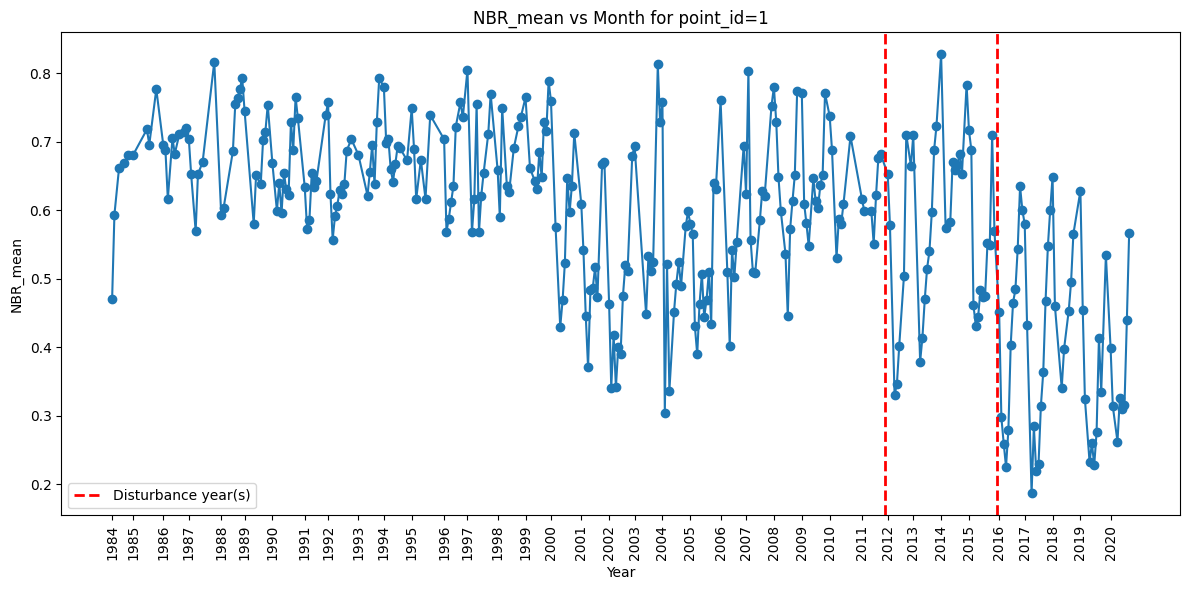

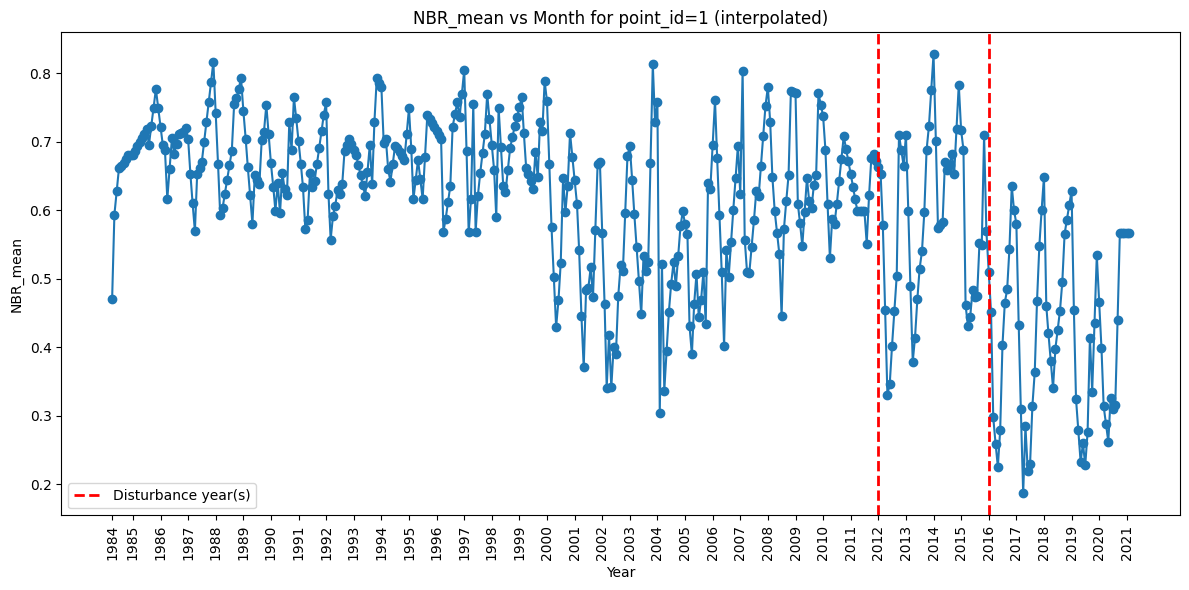

In [158]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_feature_by_month(data, point_id, feature='NBR_mean', title_suffix='', disturbance_years=None):
    # Selecting data for the given point_id
    data_point = data.loc[point_id]

    if feature not in data_point.columns:
        feature = data_point.columns[0]

    # Ensuring index is PeriodIndex (monthly)
    if not isinstance(data_point.index, pd.PeriodIndex):
        data_point.index = data_point.index.to_period('M')

    # Getting all unique years in the data
    years = sorted(set(data_point.index.year))

    # For each year, finding the first available month
    tick_positions = []
    tick_labels = []
    for year in years:
        periods_in_year = data_point.index[data_point.index.year == year]
        if len(periods_in_year) > 0:
            tick_positions.append(periods_in_year[0].to_timestamp())
            tick_labels.append(str(year))

    plt.figure(figsize=(12,6))
    plt.plot(data_point.index.to_timestamp(), data_point[feature], marker='o')
    plt.xticks(tick_positions, tick_labels, rotation=90)
    plt.xlabel('Year')
    plt.ylabel(feature)
    plt.title(f'{feature} vs Month for point_id={point_id}{title_suffix}')

    # Adding vertical red lines for disturbance years
    if disturbance_years is not None:
        for year in disturbance_years:
            plt.axvline(pd.Timestamp(f'{year}-01-01'), color='red', linestyle='--', linewidth=2, label=f'Disturbance {year}')
        # Only showing one legend entry for all lines
        handles, labels_ = plt.gca().get_legend_handles_labels()
        if handles:
            plt.legend([handles[0]], ['Disturbance year(s)'], loc='best')

    plt.tight_layout()
    plt.show()

# First plot (raw, not interpolated)
plot_feature_by_month(changepts_month, point_id=1, feature='NBR_mean', disturbance_years=[2012, 2016])

# Second plot (interpolated)
plot_feature_by_month(changepts_month_interp, point_id=1, feature='NBR_mean', title_suffix=' (interpolated)', disturbance_years=[2012, 2016])

Here, we can compare the results of filling in the months that had no data

For the non interpolated plot a different x axis labelling logic needs to be used, otherwise some years would not appear on the x axis because they have no data for January of that year

The red lines correspond to the years where there was a disturbance for this point_id

#### Aggregation by year

First, we will sort the "changepts" DataFrame by point_id and aggregate the data yearly by mean, std, min, max, median

In [159]:
changepts_stacked = changepts.reset_index().set_index(['point_id','Date']).sort_index()

# Grouping by point_id and month, and aggregating with multiple statistics
changepts_year = changepts_stacked.groupby(
    ['point_id', pd.Grouper(level=1, freq='Y')]
).agg({
    'NBR': ['mean', 'std', 'min', 'max', 'median'],
    'NDVI': ['mean', 'std', 'min', 'max', 'median']
})

# Converting DateTimeIndex to PeriodIndex
changepts_year = changepts_year.copy()
changepts_year.index = changepts_year.index.set_levels(
    [changepts_year.index.levels[0], 
     changepts_year.index.levels[1].to_period('Y')]
)

changepts_year

C:\Users\Pedro\AppData\Local\Temp\ipykernel_22792\2428147509.py:5: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  ['point_id', pd.Grouper(level=1, freq='Y')]


NBR                                              NDVI  \
                   mean       std       min       max    median      mean   
point_id Date                                                               
1        1984  0.630378  0.082079  0.470472  0.729161  0.641334  0.547491   
         1985  0.713536  0.038105  0.680864  0.776929  0.702146  0.606809   
         1986  0.691779  0.033267  0.616463  0.720653  0.700174  0.568479   
         1987  0.677912  0.074108  0.569562  0.816818  0.659908  0.555518   
         1988  0.715941  0.083242  0.563587  0.799742  0.751291  0.596083   
...                 ...       ...       ...       ...       ...       ...   
998      2017  0.389065  0.039339  0.313403  0.500860  0.390879  0.541497   
         2018  0.417721  0.060491  0.283831  0.613757  0.419110  0.550893   
         2019  0.395435  0.058762  0.305368  0.526828  0.387617  0.545788   
         2020  0.470085  0.047725  0.338581  0.550798  0.475305  0.571028   
         2021  0.444107       NaN  0.444107  0.444107  0.444107  0.589744   

                                                       
                    std       min       max    median  
point_id Date                                          
1        1984  0.085138  0.426005  0.651604  0.574660  
         1985  0.049693  0.551990  0.660766  0.593870  
         1986  0.036877  0.504291  0.610682  0.569868  
         1987  0.068800  0.475360  0.665297  0.542438  
         1988  0.073286  0.449337  0.688418  0.618974  
...                 ...       ...       ...       ...  
998      2017  0.057601  0.411066  0.645389  0.548939  
         2018  0.057972  0.401920  0.642429  0.562577  
         2019  0.064870  0.393565  0.667842  0.541165  
         2020  0.047784  0.459290  0.653776  0.574704  
         2021       NaN  0.589744  0.589744  0.589744  

[37638 rows x 10 columns]

In [160]:
# Flattening the MultiIndex columns
changepts_year.columns = ['_'.join(col).strip() for col in changepts_year.columns.values]

# Flatenning necessary
# Before flatenning:
# NBR                 NDVI
#    mean std min ...   mean std min ...
# 0   ...  ... ...      ...  ... ...
# After flatenning:
# NBR_mean NBR_std NBR_min ... NDVI_mean NDVI_std NDVI_min ...
# 0   ...  ... ...      ...  ... ...

changepts_year

NBR_mean   NBR_std   NBR_min   NBR_max  NBR_median  NDVI_mean  \
point_id Date                                                                  
1        1984  0.630378  0.082079  0.470472  0.729161    0.641334   0.547491   
         1985  0.713536  0.038105  0.680864  0.776929    0.702146   0.606809   
         1986  0.691779  0.033267  0.616463  0.720653    0.700174   0.568479   
         1987  0.677912  0.074108  0.569562  0.816818    0.659908   0.555518   
         1988  0.715941  0.083242  0.563587  0.799742    0.751291   0.596083   
...                 ...       ...       ...       ...         ...        ...   
998      2017  0.389065  0.039339  0.313403  0.500860    0.390879   0.541497   
         2018  0.417721  0.060491  0.283831  0.613757    0.419110   0.550893   
         2019  0.395435  0.058762  0.305368  0.526828    0.387617   0.545788   
         2020  0.470085  0.047725  0.338581  0.550798    0.475305   0.571028   
         2021  0.444107       NaN  0.444107  0.444107    0.444107   0.589744   

               NDVI_std  NDVI_min  NDVI_max  NDVI_median  
point_id Date                                             
1        1984  0.085138  0.426005  0.651604     0.574660  
         1985  0.049693  0.551990  0.660766     0.593870  
         1986  0.036877  0.504291  0.610682     0.569868  
         1987  0.068800  0.475360  0.665297     0.542438  
         1988  0.073286  0.449337  0.688418     0.618974  
...                 ...       ...       ...          ...  
998      2017  0.057601  0.411066  0.645389     0.548939  
         2018  0.057972  0.401920  0.642429     0.562577  
         2019  0.064870  0.393565  0.667842     0.541165  
         2020  0.047784  0.459290  0.653776     0.574704  
         2021       NaN  0.589744  0.589744     0.589744  

[37638 rows x 10 columns]

In [161]:
# Filtering changepts_year to keep only valid point_id's from ref
# Getting valid point_ids
valid_point_ids = ref[ref['valid'] == True].index

# Filtering changepts_year
changepts_year_valid = changepts_year.loc[changepts_year.index.get_level_values('point_id').isin(valid_point_ids)]

# Displaying the result
display(changepts_year_valid)

# Displayingthe number of unique point_id's (level 0 of the MultiIndex)
num_point_ids = changepts_year_valid.index.get_level_values(0).nunique()
print("Number of unique valid point_id's:", num_point_ids)

NBR_mean   NBR_std   NBR_min   NBR_max  NBR_median  NDVI_mean  \
point_id Date                                                                  
1        1984  0.630378  0.082079  0.470472  0.729161    0.641334   0.547491   
         1985  0.713536  0.038105  0.680864  0.776929    0.702146   0.606809   
         1986  0.691779  0.033267  0.616463  0.720653    0.700174   0.568479   
         1987  0.677912  0.074108  0.569562  0.816818    0.659908   0.555518   
         1988  0.715941  0.083242  0.563587  0.799742    0.751291   0.596083   
...                 ...       ...       ...       ...         ...        ...   
998      2017  0.389065  0.039339  0.313403  0.500860    0.390879   0.541497   
         2018  0.417721  0.060491  0.283831  0.613757    0.419110   0.550893   
         2019  0.395435  0.058762  0.305368  0.526828    0.387617   0.545788   
         2020  0.470085  0.047725  0.338581  0.550798    0.475305   0.571028   
         2021  0.444107       NaN  0.444107  0.444107    0.444107   0.589744   

               NDVI_std  NDVI_min  NDVI_max  NDVI_median  
point_id Date                                             
1        1984  0.085138  0.426005  0.651604     0.574660  
         1985  0.049693  0.551990  0.660766     0.593870  
         1986  0.036877  0.504291  0.610682     0.569868  
         1987  0.068800  0.475360  0.665297     0.542438  
         1988  0.073286  0.449337  0.688418     0.618974  
...                 ...       ...       ...          ...  
998      2017  0.057601  0.411066  0.645389     0.548939  
         2018  0.057972  0.401920  0.642429     0.562577  
         2019  0.064870  0.393565  0.667842     0.541165  
         2020  0.047784  0.459290  0.653776     0.574704  
         2021       NaN  0.589744  0.589744     0.589744  

[25016 rows x 10 columns]

Number of unique valid point_id's: 664


"Number of unique valid point_id's: 664" checks out with the number of valid point_id's in ref (Seen in Task 2)

In [162]:
import pandas as pd

# Geting all unique point_ids
point_ids = changepts_year.index.get_level_values('point_id').unique()

# Getting the full range of months in your data
all_months = pd.period_range(
    start=changepts_year.index.get_level_values('Date').min(),
    end=changepts_year.index.get_level_values('Date').max(),
    freq='Y'
)

# Creating a MultiIndex with all combinations of point_id and month
full_index = pd.MultiIndex.from_product(
    [point_ids, all_months],
    names=['point_id', 'Date']
)

# Reindexing and interpolating
changepts_year_full = changepts_year.reindex(full_index)
changepts_year_interp = changepts_year_full.groupby(level=0).apply(lambda df: df.interpolate())

changepts_year_interp.index = changepts_year_interp.index.droplevel(0)

# Now changepts_year_interp has interpolated values for all months for each point_id
changepts_year_interp

NBR_mean   NBR_std   NBR_min   NBR_max  NBR_median  NDVI_mean  \
point_id Date                                                                  
1        1984  0.630378  0.082079  0.470472  0.729161    0.641334   0.547491   
         1985  0.713536  0.038105  0.680864  0.776929    0.702146   0.606809   
         1986  0.691779  0.033267  0.616463  0.720653    0.700174   0.568479   
         1987  0.677912  0.074108  0.569562  0.816818    0.659908   0.555518   
         1988  0.715941  0.083242  0.563587  0.799742    0.751291   0.596083   
...                 ...       ...       ...       ...         ...        ...   
998      2017  0.389065  0.039339  0.313403  0.500860    0.390879   0.541497   
         2018  0.417721  0.060491  0.283831  0.613757    0.419110   0.550893   
         2019  0.395435  0.058762  0.305368  0.526828    0.387617   0.545788   
         2020  0.470085  0.047725  0.338581  0.550798    0.475305   0.571028   
         2021  0.444107  0.047725  0.444107  0.444107    0.444107   0.589744   

               NDVI_std  NDVI_min  NDVI_max  NDVI_median  
point_id Date                                             
1        1984  0.085138  0.426005  0.651604     0.574660  
         1985  0.049693  0.551990  0.660766     0.593870  
         1986  0.036877  0.504291  0.610682     0.569868  
         1987  0.068800  0.475360  0.665297     0.542438  
         1988  0.073286  0.449337  0.688418     0.618974  
...                 ...       ...       ...          ...  
998      2017  0.057601  0.411066  0.645389     0.548939  
         2018  0.057972  0.401920  0.642429     0.562577  
         2019  0.064870  0.393565  0.667842     0.541165  
         2020  0.047784  0.459290  0.653776     0.574704  
         2021  0.047784  0.589744  0.589744     0.589744  

[37924 rows x 10 columns]

Months with no data have been filled in by interpolation

First aggregation/feature calculation, then interpolation to fill missing feature values.

This is more robust and interpretable for machine learning.

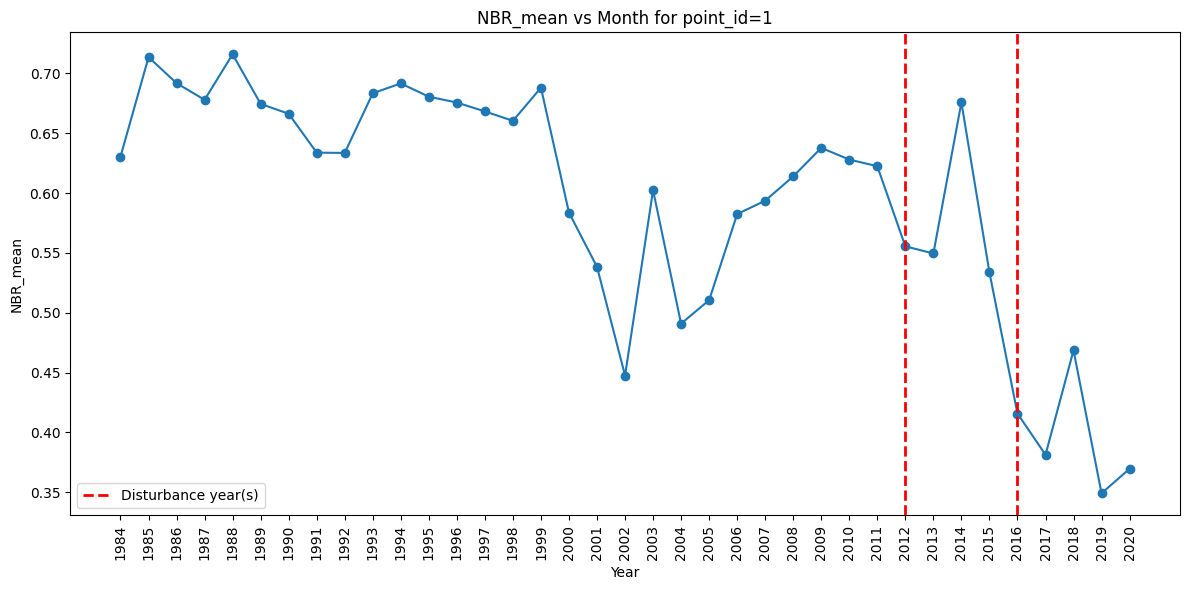

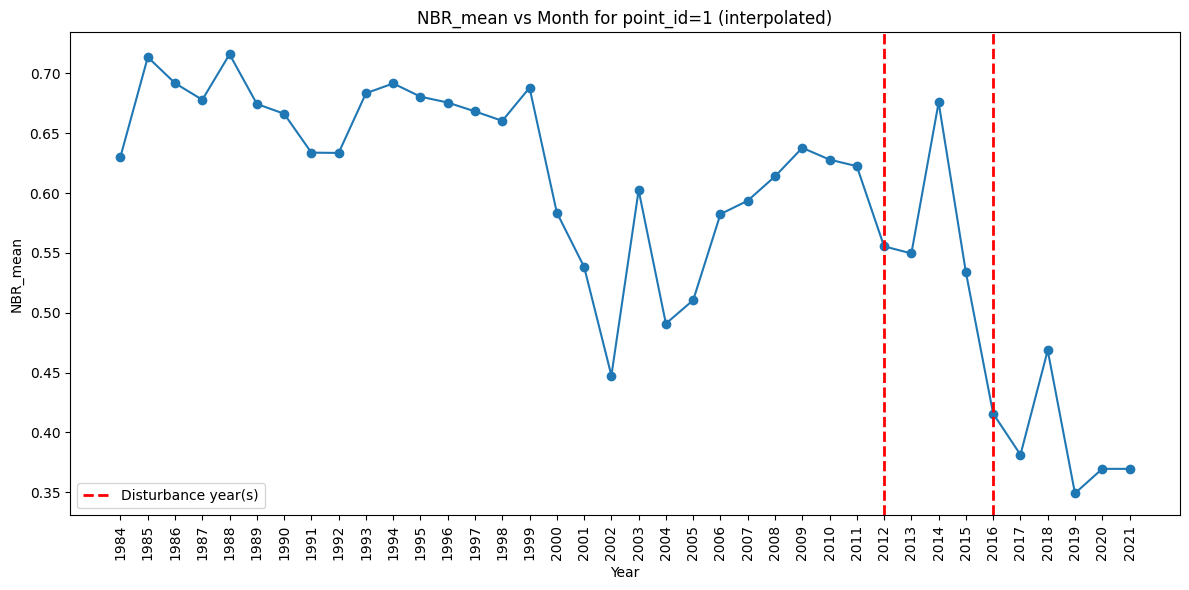

In [163]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_feature_by_month(data, point_id, feature='NBR_mean', title_suffix='', disturbance_years=None):
    # Selecting data for the given point_id
    data_point = data.loc[point_id]

    if feature not in data_point.columns:
        feature = data_point.columns[0]

    # Ensuring index is PeriodIndex (monthly)
    if not isinstance(data_point.index, pd.PeriodIndex):
        data_point.index = data_point.index.to_period('Y')

    # Getting all unique years in the data
    years = sorted(set(data_point.index.year))

    # For each year, finding the first available month
    tick_positions = []
    tick_labels = []
    for year in years:
        periods_in_year = data_point.index[data_point.index.year == year]
        if len(periods_in_year) > 0:
            tick_positions.append(periods_in_year[0].to_timestamp())
            tick_labels.append(str(year))

    plt.figure(figsize=(12,6))
    plt.plot(data_point.index.to_timestamp(), data_point[feature], marker='o')
    plt.xticks(tick_positions, tick_labels, rotation=90)
    plt.xlabel('Year')
    plt.ylabel(feature)
    plt.title(f'{feature} vs Month for point_id={point_id}{title_suffix}')

    # Adding vertical red lines for disturbance years
    if disturbance_years is not None:
        for year in disturbance_years:
            plt.axvline(pd.Timestamp(f'{year}-01-01'), color='red', linestyle='--', linewidth=2, label=f'Disturbance {year}')
        # Only showing one legend entry for all lines
        handles, labels_ = plt.gca().get_legend_handles_labels()
        if handles:
            plt.legend([handles[0]], ['Disturbance year(s)'], loc='best')

    plt.tight_layout()
    plt.show()

# First plot (raw, not interpolated)
plot_feature_by_month(changepts_year, point_id=1, feature='NBR_mean', disturbance_years=[2012, 2016])

# Second plot (interpolated)
plot_feature_by_month(changepts_year_interp, point_id=1, feature='NBR_mean', title_suffix=' (interpolated)', disturbance_years=[2012, 2016])

Here, we can compare the results of filling in the years that had no data

The red lines correspond to the years where there was a disturbance for this point_id

#### Dimentionality Reduction in changepoints

In [164]:
# 1. Prepare the feature matrix and labels
features_by_point = changepts_month_interp.groupby('point_id').mean()

# Get labels from ref_processed - we need to aggregate causes by point_id
# Since ref_processed has (point_id, breaks) MultiIndex, we need to group by point_id
labels_by_point = ref_processed.groupby(level=0)['causes'].apply(lambda x: x.iloc[0] if len(x) > 0 else 'unknown')

# Align the labels with features_by_point index
labels = labels_by_point.reindex(features_by_point.index).fillna('unknown')

# 2. Factorize labels ONCE, to use everywhere
label_codes, label_names = pd.factorize(labels)

# for plotting only labeled data
mask = labels != 'unknown'

##### PCA

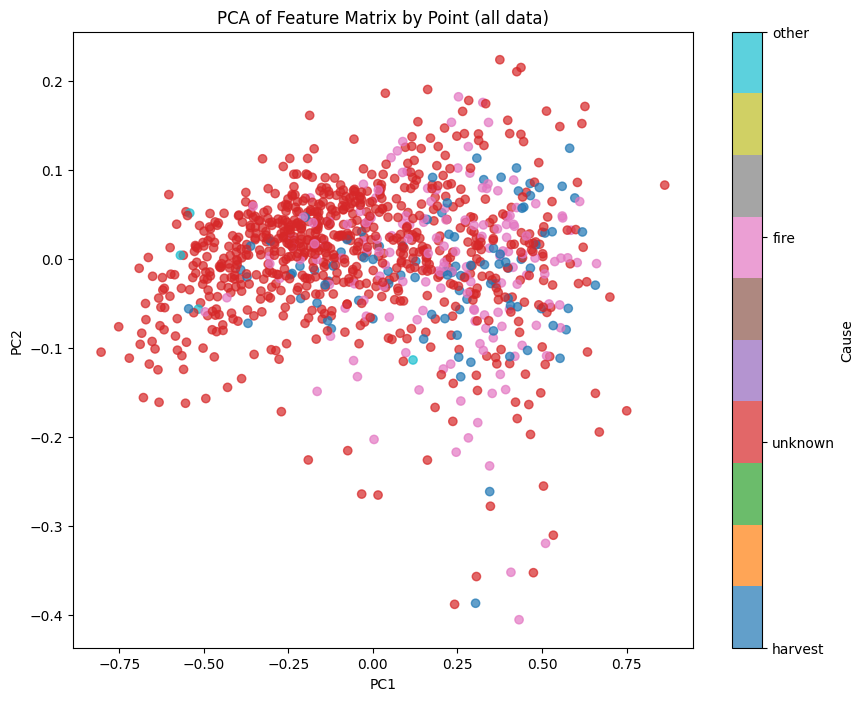

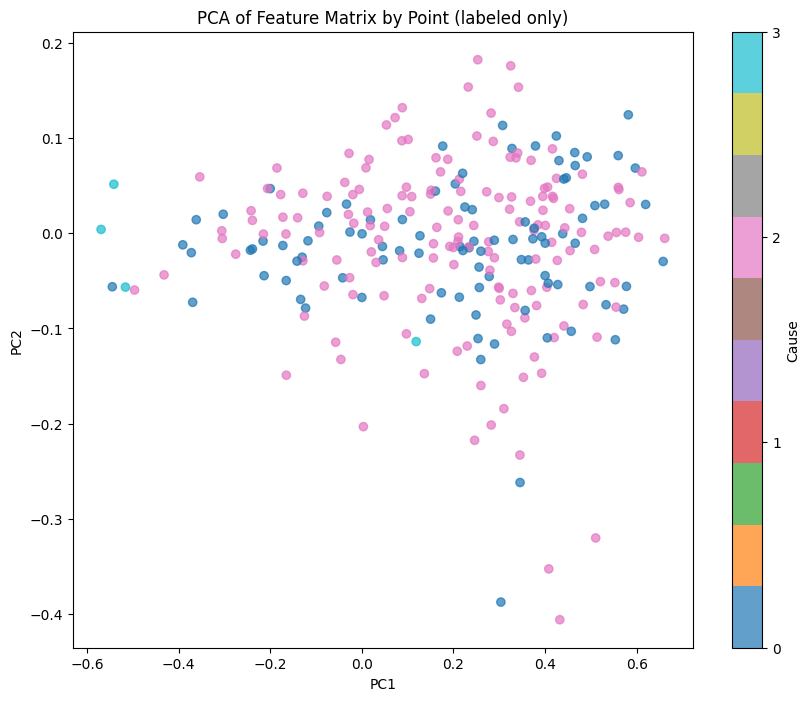

In [165]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
reduced_pca = pca.fit_transform(features_by_point)

import matplotlib.pyplot as plt

pca = PCA(n_components=2)
reduced_pca = pca.fit_transform(features_by_point)

# 1. Plotting all data (labeled + unlabeled)
plt.figure(figsize=(10, 8))
scatter_all = plt.scatter(reduced_pca[:, 0], reduced_pca[:, 1], c=label_codes, cmap='tab10', alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of Feature Matrix by Point (all data)')
cbar = plt.colorbar(scatter_all, ticks=range(len(label_names)), label='Cause')
cbar.ax.set_yticklabels(label_names)
plt.show()

# 2. Plotting only labeled data
plt.figure(figsize=(10, 8))
plt.scatter(reduced_pca[mask, 0], reduced_pca[mask, 1], c=label_codes[mask], cmap='tab10', alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of Feature Matrix by Point (labeled only)')
plt.colorbar(ticks=range(len(label_names)), label='Cause')
plt.show()

##### t-SNE

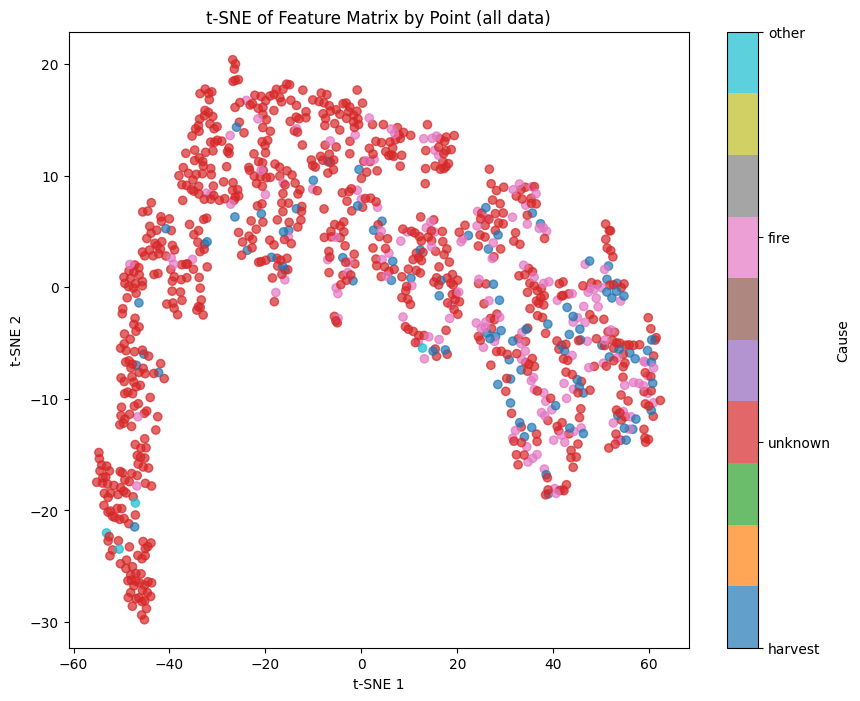

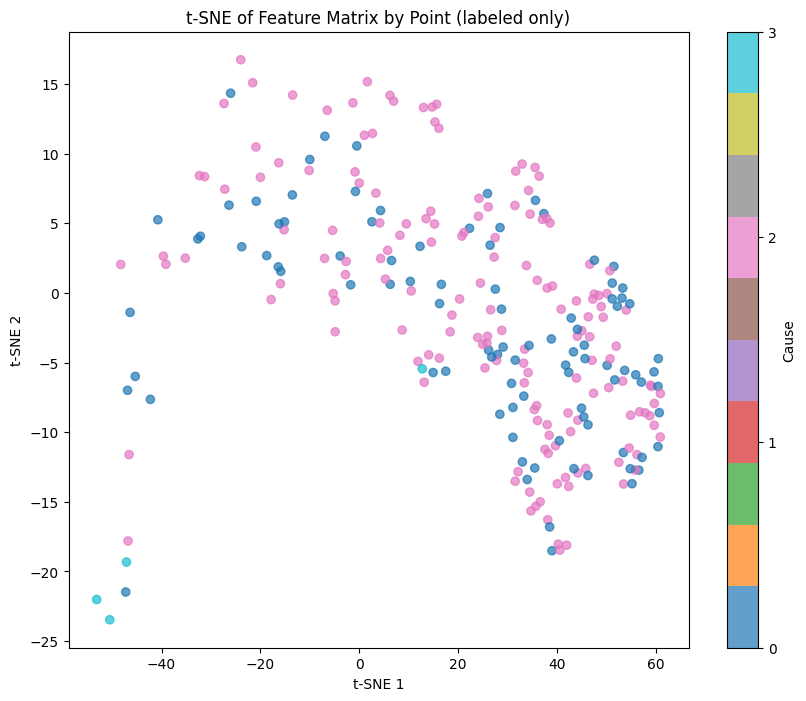

In [166]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42)
reduced_tsne = tsne.fit_transform(features_by_point)

# 1. Plotting all data (labeled + unlabeled)
plt.figure(figsize=(10, 8))
scatter_all = plt.scatter(reduced_tsne[:, 0], reduced_tsne[:, 1], c=label_codes, cmap='tab10', alpha=0.7)
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('t-SNE of Feature Matrix by Point (all data)')
cbar = plt.colorbar(scatter_all, ticks=range(len(label_names)), label='Cause')
cbar.ax.set_yticklabels(label_names)
plt.show()

# 2. Plotting only labeled data
plt.figure(figsize=(10, 8))
plt.scatter(reduced_tsne[mask, 0], reduced_tsne[mask, 1], c=label_codes[mask], cmap='tab10', alpha=0.7)
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('t-SNE of Feature Matrix by Point (labeled only)')
plt.colorbar(ticks=range(len(label_names)), label='Cause')
plt.show()

## Task 4 – Tuning and training of the classifier

- Prepare target variable by creating disturbance labels based on `(point_id, year)` pairs
- Split data into training and test sets with stratification
- Train Random Forest classifier with various approaches:
  - Standard training
  - Class weight balancing
  - SMOTE resampling for imbalanced data
- Evaluate model performance using accuracy, precision, recall, and F1-score
- Analyze feature importance to understand key predictors

#### Example 1 (monthly)

In [167]:
display(ref_processed)
display(changepts_month_interp)


# Getting the DataFrame for point_id=1
df_point1 = changepts_month_interp.loc[1]

# Filtering for years 2011 and 2012
df_filtered = df_point1[df_point1.index.year.isin([2011, 2012])]

display(df_filtered)

causes
point_id breaks         
1        2012    harvest
         2016    harvest
50       2004       fire
57       2005      other
70       2012       fire
...                  ...
979      1992    unknown
988      2001    unknown
989      1987    unknown
         2004    unknown
991      1997    unknown

[732 rows x 1 columns]

NBR_mean   NBR_std   NBR_min   NBR_max  NBR_median  \
point_id Date                                                          
1        1984-04  0.470472       NaN  0.470472  0.470472    0.470472   
         1984-05  0.593581       NaN  0.593581  0.593581    0.593581   
         1984-06  0.627871       NaN  0.627871  0.627871    0.627871   
         1984-07  0.662161       NaN  0.662161  0.662161    0.662161   
         1984-08  0.665273       NaN  0.648409  0.695661    0.651748   
...                    ...       ...       ...       ...         ...   
998      2020-10  0.518413  0.045799  0.486029  0.550798    0.518413   
         2020-11  0.481517  0.034427  0.481517  0.481517    0.481517   
         2020-12  0.528298  0.023055  0.511995  0.544600    0.528298   
         2021-01  0.486203  0.023055  0.478051  0.494354    0.486203   
         2021-02  0.444107  0.023055  0.444107  0.444107    0.444107   

                  NDVI_mean  NDVI_std  NDVI_min  NDVI_max  NDVI_median  
point_id Date                                                           
1        1984-04   0.426005       NaN  0.426005  0.426005     0.426005  
         1984-05   0.437981       NaN  0.437981  0.437981     0.437981  
         1984-06   0.522455       NaN  0.522455  0.522455     0.522455  
         1984-07   0.606930       NaN  0.606930  0.606930     0.606930  
         1984-08   0.601275       NaN  0.577169  0.629267     0.597387  
...                     ...       ...       ...       ...          ...  
998      2020-10   0.611245  0.050024  0.575873  0.646618     0.611245  
         2020-11   0.500545  0.055643  0.500545  0.500545     0.500545  
         2020-12   0.574112  0.061262  0.530793  0.617431     0.574112  
         2021-01   0.581928  0.061262  0.560268  0.603587     0.581928  
         2021-02   0.589744  0.061262  0.589744  0.589744     0.589744  

[442114 rows x 10 columns]

,NBR_mean,NBR_std,NBR_min,NBR_max,NBR_median,NDVI_mean,NDVI_std,NDVI_min,NDVI_max,NDVI_median
Date,,,,,,,,,,
2011-01,0.652872,0.040071,0.638307,0.667437,0.652872,0.615727,0.027387,0.612266,0.619188,0.615727
2011-02,0.634442,0.036262,0.627160,0.641725,0.634442,0.605090,0.032437,0.603360,0.606821,0.605090
2011-03,0.616012,0.032453,0.616012,0.616012,0.616012,0.594454,0.037487,0.594454,0.594454,0.594454
2011-04,0.598401,0.028645,0.578146,0.618656,0.598401,0.580143,0.042538,0.550064,0.610221,0.580143
2011-05,0.598781,0.033568,0.585278,0.612284,0.598781,0.570262,0.034022,0.550210,0.590315,0.570262
2011-06,0.599160,0.038492,0.592409,0.605912,0.599160,0.560382,0.025506,0.550356,0.570409,0.560382
2011-07,0.599540,0.043416,0.599540,0.599540,0.599540,0.550502,0.016990,0.550502,0.550502,0.550502
2011-08,0.551330,0.048339,0.517149,0.585511,0.551330,0.597812,0.008475,0.591820,0.603805,0.597812
2011-09,0.621697,0.062389,0.621697,0.621697,0.621697,0.619077,0.021664,0.619077,0.619077,0.619077


We can change these two variables to interactively see the change in NBR or NDVI in a specific year for a specific point_id:

In [194]:
point_id = 1
years_of_interest = [2015, 2016]

index_feature = "NBR"      # or "NDVI"
stat_feature = "mean"      # or "std", "min", "max", "median"

In [195]:
a = changepts_month_interp.loc[1][changepts_month_interp.loc[1].index.year == 1984]
a['NBR_mean']

Date
1984-04    0.470472
1984-05    0.593581
1984-06    0.627871
1984-07    0.662161
1984-08    0.665273
1984-09    0.668384
1984-10    0.674833
1984-11    0.681281
1984-12    0.681072
Freq: M, Name: NBR_mean, dtype: float64

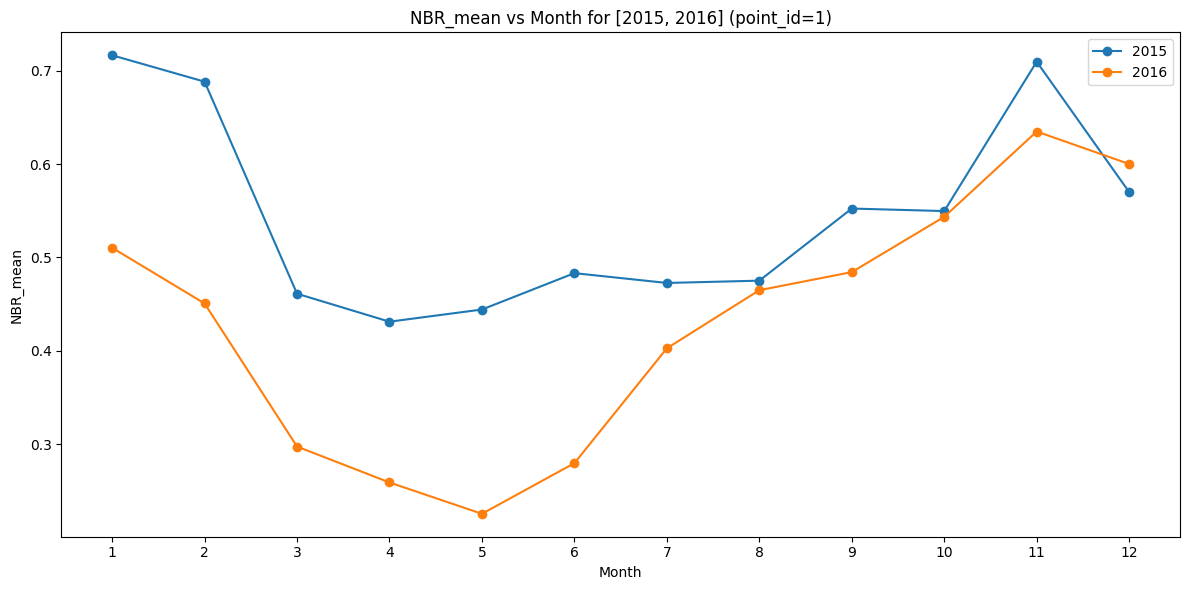

In [196]:
feature_col = f"{index_feature}_{stat_feature}"

filtered_point = changepts_month_interp.loc[point_id]

plt.figure(figsize=(12, 6))
for year in years_of_interest:
    df_year = filtered_point[filtered_point.index.year == year]
    plt.plot(df_year.index.month, df_year[feature_col], marker='o', label=str(year))

plt.xlabel('Month')
plt.ylabel(feature_col)
plt.title(f'{feature_col} vs Month for {years_of_interest} (point_id={point_id})')
plt.legend()
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

#### Example 2 (yearly)

In [171]:
display(ref_processed)
display(changepts_year_interp)

causes
point_id breaks         
1        2012    harvest
         2016    harvest
50       2004       fire
57       2005      other
70       2012       fire
...                  ...
979      1992    unknown
988      2001    unknown
989      1987    unknown
         2004    unknown
991      1997    unknown

[732 rows x 1 columns]

NBR_mean   NBR_std   NBR_min   NBR_max  NBR_median  NDVI_mean  \
point_id Date                                                                  
1        1984  0.630378  0.082079  0.470472  0.729161    0.641334   0.547491   
         1985  0.713536  0.038105  0.680864  0.776929    0.702146   0.606809   
         1986  0.691779  0.033267  0.616463  0.720653    0.700174   0.568479   
         1987  0.677912  0.074108  0.569562  0.816818    0.659908   0.555518   
         1988  0.715941  0.083242  0.563587  0.799742    0.751291   0.596083   
...                 ...       ...       ...       ...         ...        ...   
998      2017  0.389065  0.039339  0.313403  0.500860    0.390879   0.541497   
         2018  0.417721  0.060491  0.283831  0.613757    0.419110   0.550893   
         2019  0.395435  0.058762  0.305368  0.526828    0.387617   0.545788   
         2020  0.470085  0.047725  0.338581  0.550798    0.475305   0.571028   
         2021  0.444107  0.047725  0.444107  0.444107    0.444107   0.589744   

               NDVI_std  NDVI_min  NDVI_max  NDVI_median  
point_id Date                                             
1        1984  0.085138  0.426005  0.651604     0.574660  
         1985  0.049693  0.551990  0.660766     0.593870  
         1986  0.036877  0.504291  0.610682     0.569868  
         1987  0.068800  0.475360  0.665297     0.542438  
         1988  0.073286  0.449337  0.688418     0.618974  
...                 ...       ...       ...          ...  
998      2017  0.057601  0.411066  0.645389     0.548939  
         2018  0.057972  0.401920  0.642429     0.562577  
         2019  0.064870  0.393565  0.667842     0.541165  
         2020  0.047784  0.459290  0.653776     0.574704  
         2021  0.047784  0.589744  0.589744     0.589744  

[37924 rows x 10 columns]

In [172]:
# Getting the DataFrame for point_id=1
df_point1 = changepts_year_interp.loc[1]

# Filtering for years 2011 and 2012
df_filtered = df_point1[df_point1.index.year.isin([2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020])]

display(df_filtered)

,NBR_mean,NBR_std,NBR_min,NBR_max,NBR_median,NDVI_mean,NDVI_std,NDVI_min,NDVI_max,NDVI_median
Date,,,,,,,,,,
2011,0.622427,0.062312,0.517149,0.741270,0.616012,0.590344,0.029841,0.550064,0.630262,0.594454
2012,0.555468,0.152870,0.329908,0.765019,0.593398,0.582069,0.053138,0.520254,0.664517,0.576599
2013,0.549493,0.121576,0.349954,0.740020,0.530390,0.629238,0.072233,0.509263,0.754654,0.636300
2014,0.675722,0.084894,0.546580,0.827848,0.666326,0.645855,0.072881,0.454411,0.741715,0.652504
2015,0.533807,0.096542,0.409726,0.735558,0.507375,0.619949,0.049517,0.492016,0.721549,0.621005
2016,0.415740,0.135716,0.191962,0.707652,0.438088,0.566411,0.061065,0.459634,0.712169,0.569654
2017,0.381286,0.155992,0.111966,0.630218,0.359654,0.540918,0.077288,0.313989,0.669388,0.527025
2018,0.468511,0.081429,0.299846,0.648966,0.480357,0.575089,0.054274,0.455554,0.662223,0.584614
2019,0.349085,0.151215,0.192975,0.643197,0.277191,0.513562,0.068024,0.425632,0.665855,0.485010


Here we can see that, even though a disturbance occurred in 2012 and 2016, the years with the lowest NBR and NDVI (mean) values are the following years (2013 and 2017)

#### Random Forest

##### Preparation of the target variable (point_id, year)

In [173]:
# For changepts_year_interp: converting Period to int (year)
cyi = changepts_year_interp.copy()
cyi.index = cyi.index.set_levels([
    cyi.index.levels[0],  # point_id
    cyi.index.levels[1].astype(str).astype(int)  # year as int
])

# For ref_processed: converting string to int
rp = ref_processed.copy()
rp.index = rp.index.set_levels([
    rp.index.levels[0],             # point_id
    rp.index.levels[1].astype(int)  # year as int
])

### Changepts_year_interp doesnt have disturbance (80, 1983) cause (raw) changepts.index starts in 1984

disturbed_pairs = set(rp.index)
cyi['disturbance'] = [1 if idx in disturbed_pairs else 0 for idx in cyi.index]
print(cyi['disturbance'].value_counts())

disturbance
0    37193
1      731
Name: count, dtype: int64


Dataset is very unbalanced towards 0 (no disturbance observed). This means the model's accuracy won't be a good measure of its performance

##### Splitting into features and target

In [174]:
# Excluding the target column from features
X_features = cyi[['NBR_mean',
 'NBR_std',
 'NBR_min',
 'NBR_max',
 'NBR_median',
 'NDVI_mean',
 'NDVI_std',
 'NDVI_min',
 'NDVI_max',
 'NDVI_median']]
y = cyi['disturbance']

# X_features is a DataFrame
# y is a Series

##### Train/Test split

In [197]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_features, y, test_size=0.2, random_state=42, stratify=y
)

# X_train, y_train size is 30339 point_ids
# X_test, y_test size is 7585 point_ids

##### Random Forest training

In [198]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(random_state=42, class_weight='balanced')
clf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

##### Model evaluation

In [199]:
from sklearn.metrics import classification_report, accuracy_score

y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9819380355965722
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      7439
           1       0.68      0.12      0.20       146

    accuracy                           0.98      7585
   macro avg       0.83      0.56      0.59      7585
weighted avg       0.98      0.98      0.98      7585



##### Model resampling with SMOTE, retraining and reevaluation

In [178]:
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report

# Creating the resampled dataset
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Training the model on the resampled data
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_resampled, y_train_resampled)

# Predicting and evaluating
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      7439
           1       0.23      0.34      0.28       146

    accuracy                           0.97      7585
   macro avg       0.61      0.66      0.63      7585
weighted avg       0.97      0.97      0.97      7585



##### Analysis of the importance of each feature

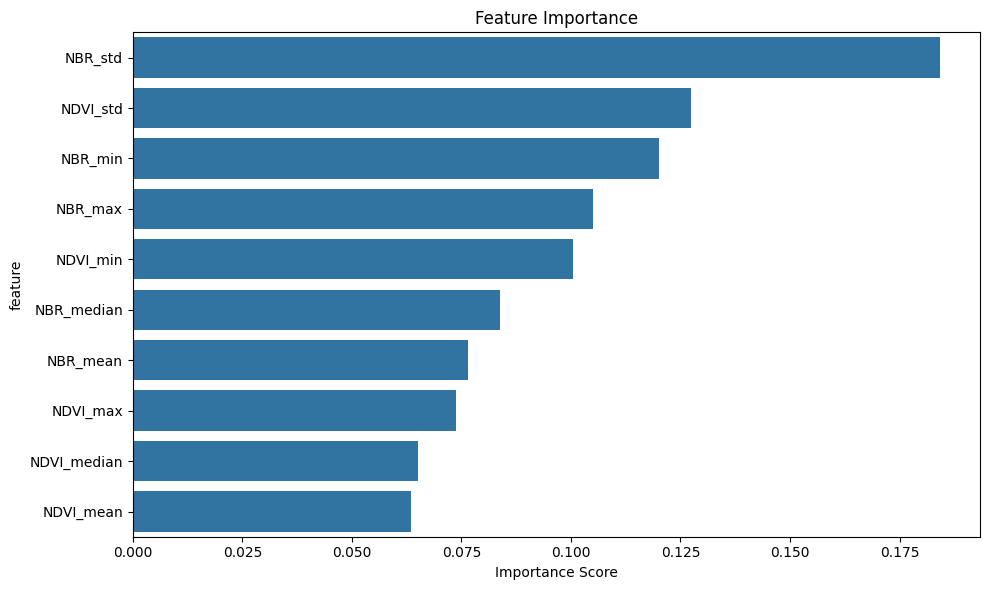


Feature Importance Scores:
NBR_std: 0.1842
NDVI_std: 0.1273
NBR_min: 0.1201
NBR_max: 0.1051
NDVI_min: 0.1005
NBR_median: 0.0838
NBR_mean: 0.0765
NDVI_max: 0.0738
NDVI_median: 0.0650
NDVI_mean: 0.0636


In [179]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Getting feature importances from the model
importances = clf.feature_importances_
feature_names = X_features.columns  # Your feature names from the training data

# Creating a dataframe of features and their importance scores
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
})

# Sorting by importance
feature_importance = feature_importance.sort_values('importance', ascending=False)

# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance)
plt.title('Feature Importance')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# Printing the actual values
print("\nFeature Importance Scores:")
for idx, row in feature_importance.iterrows():
    print(f"{row['feature']}: {row['importance']:.4f}")

##### Testing the model interactively

In this section, each model can be tested with point_id and year of the user's choosing

In [180]:
# Variables to be changed to test the model
point_id = 1
year = '2012'

In [181]:
features = changepts_year_interp.loc[(point_id, year)].values
list(features)

y_pred = clf.predict([list(features)])
y_pred

C:\Users\Pedro\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([1], dtype=int64)

## Task 5 – Visualization of the classification results

- Create confusion matrix to visualize model performance
- Generate violin plots showing NBR/NDVI distributions by cause and invalidation_cause

##### Confusion matrix

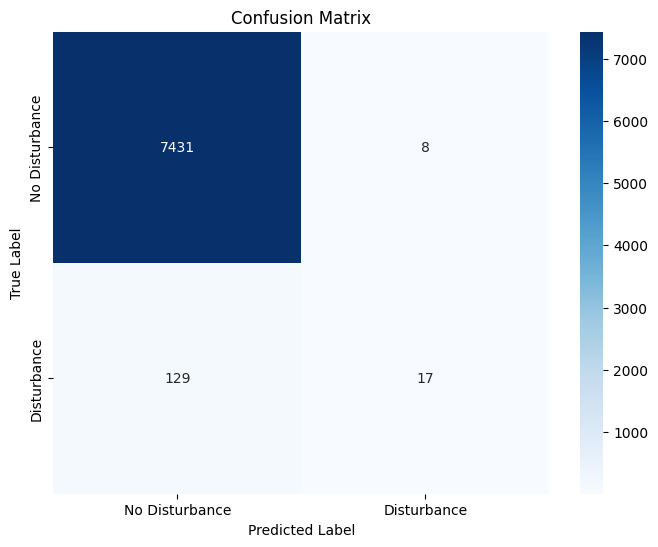

In [200]:
# Getting predictions for the entire test set
y_pred = clf.predict(X_test)

# Creating the confusion matrix plot
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Getting the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plotting
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disturbance', 'Disturbance'],
            yticklabels=['No Disturbance', 'Disturbance'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

##### Violin plot of NBR/NDVI by cause/invalidation_cause

C:\Users\Pedro\AppData\Local\Temp\ipykernel_22792\4071324133.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=merged_exploded, x='causes', y='NBR', palette=COLORS_DISTURBANCE)


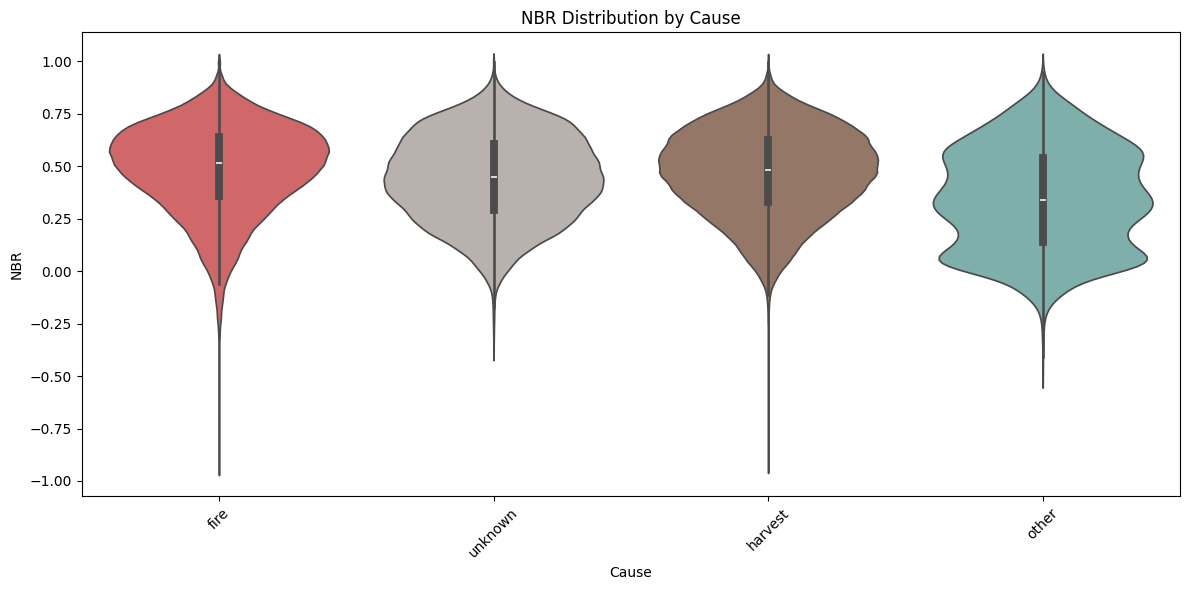

In [183]:
# resetting index of ref_exploded data created earlier
ref_exploded_reset = ref_exploded.reset_index()
changepts_reset = changepts.reset_index()

# Merging with changepts data
merged_exploded = changepts_reset.merge(ref_exploded_reset, on='point_id', how='left')

# Creating violin plots for NBR by cause (exploded)
plt.figure(figsize=(12, 6))
sns.violinplot(data=merged_exploded, x='causes', y='NBR', palette=COLORS_DISTURBANCE)
plt.title('NBR Distribution by Cause')
plt.xlabel('Cause')
plt.ylabel('NBR')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\Pedro\AppData\Local\Temp\ipykernel_22792\2703226072.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=merged_exploded, x='causes', y='NDVI', palette=COLORS_DISTURBANCE)


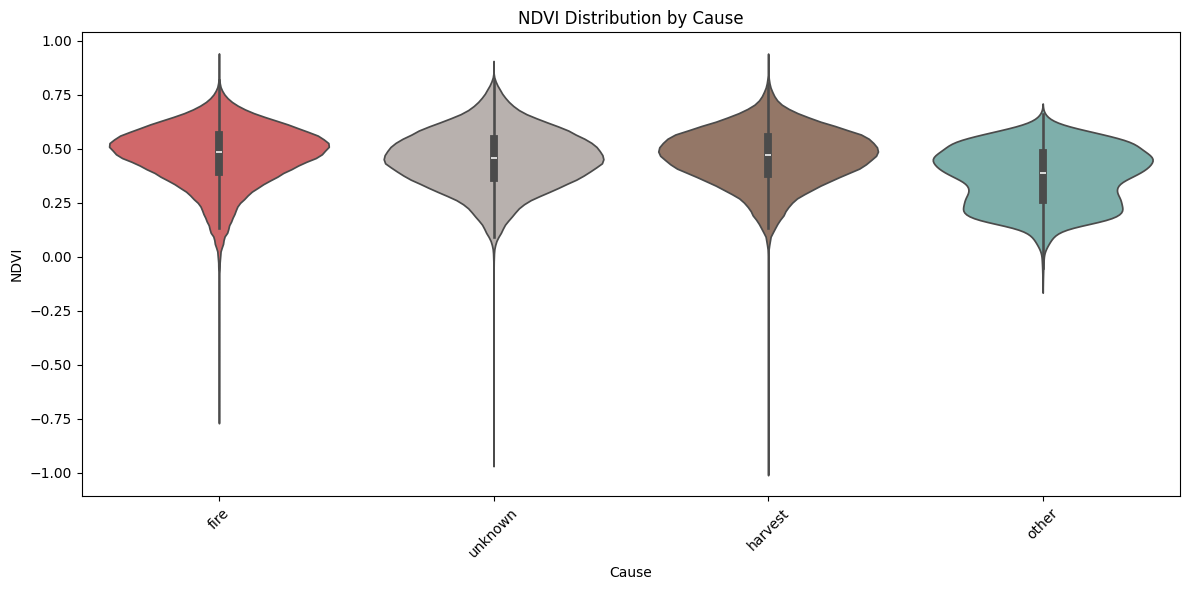

In [184]:
# Creating violin plots for NDVI by cause (exploded)
plt.figure(figsize=(12, 6))
sns.violinplot(data=merged_exploded, x='causes', y='NDVI', palette=COLORS_DISTURBANCE)
plt.title('NDVI Distribution by Cause')
plt.xlabel('Cause')
plt.ylabel('NDVI')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()